# Spatiotemporal Validation and Diagnostic Report: Integration of Meteorological and Air Quality Layers (SIMA–PurpleAir)

In [17]:
from pathlib import Path

import matplotlib.dates as mdates
import matplotlib.pyplot as plt
from cycler import cycler
from matplotlib import font_manager

FUENTES_SERIF = ["Times New Roman", "Times", "Liberation Serif", "Nimbus Roman", "DejaVu Serif"]
_instaladas = {f.name for f in font_manager.fontManager.ttflist}
if "Times New Roman" not in _instaladas:
    _alterna = next((f for f in FUENTES_SERIF if f in _instaladas), "la serif por defecto")
    print(f"Aviso: Times New Roman no está instalada; se usará {_alterna}.")

COLORES = {"SIMA": "#1F4E79", "PurpleAir": "#7B3FA0", "Diferencia": "#C0392B", "Neutro": "#4D4D4D",
           "PM2.5": "#E69F00", "PM10": "#2E8B57"}

plt.rcParams.update({
    # Tipografía
    "font.family": "serif",
    "font.serif": FUENTES_SERIF,
    "mathtext.fontset": "stix",                # subíndices y µg/m³ con aspecto Times
    "font.size": 16,
    "axes.titlesize": 20, "axes.titleweight": "bold", "axes.titlepad": 14,
    "axes.labelsize": 18, "axes.labelweight": "bold", "axes.labelpad": 8,
    "xtick.labelsize": 15, "ytick.labelsize": 15,
    "legend.fontsize": 14, "legend.title_fontsize": 15,
    "figure.titlesize": 22, "figure.titleweight": "bold",
    # Fondo blanco y sin cuadrícula
    "figure.facecolor": "white", "axes.facecolor": "white", "savefig.facecolor": "white",
    "axes.grid": False,
    "axes.spines.top": False, "axes.spines.right": False,
    "axes.edgecolor": "black", "axes.linewidth": 1.2,
    "xtick.major.size": 6, "ytick.major.size": 6,
    "xtick.major.width": 1.2, "ytick.major.width": 1.2,
    # Tamaño y exportación
    "figure.figsize": (14, 6), "figure.dpi": 100,
    "savefig.dpi": 300, "savefig.bbox": "tight",
    # Líneas, marcadores y leyendas
    "lines.linewidth": 2.0, "lines.markersize": 6,
    "legend.frameon": False,
    "axes.prop_cycle": cycler(color=[COLORES["SIMA"], COLORES["PurpleAir"], COLORES["Diferencia"],
                                     "#2E8B57", "#E69F00", "#56B4E9"]),
    # Boxplots
    "boxplot.boxprops.linewidth": 1.5, "boxplot.whiskerprops.linewidth": 1.5,
    "boxplot.capprops.linewidth": 1.5,
    "boxplot.medianprops.color": "black", "boxplot.medianprops.linewidth": 2.2,
    "boxplot.flierprops.marker": "o", "boxplot.flierprops.markersize": 4,
    "boxplot.flierprops.markeredgecolor": COLORES["Neutro"],
})

# Textos en inglés para ejes y títulos
ETIQUETA = {"PM2.5": r"PM$_{2.5}$", "PM10": r"PM$_{10}$"}
EJE_CONC = r"Concentration ($\mu$g/m$^3$)"
EJE_DIF = r"Difference PA $-$ SIMA ($\mu$g/m$^3$)"
# Para gráficas de pastel: ax.pie(valores, labels=..., **ESTILO_PASTEL)
ESTILO_PASTEL = {"wedgeprops": {"edgecolor": "white", "linewidth": 1.5},
                 "textprops": {"fontsize": 15}, "autopct": "%1.1f%%", "startangle": 90}
DIR_FIGURAS = Path("figuras")


def formato_fechas(ax):
    localizador = mdates.AutoDateLocator(minticks=4, maxticks=10)
    ax.xaxis.set_major_locator(localizador)
    ax.xaxis.set_major_formatter(mdates.ConciseDateFormatter(localizador))
    ax.set_xlabel("Date")


def guardar(fig, nombre):
    """Guarda la figura en PNG a 300 dpi dentro de la carpeta 'figuras'."""
    DIR_FIGURAS.mkdir(exist_ok=True)
    fig.savefig(DIR_FIGURAS / f"{nombre}.png")

### Geographic Coverage Alignment of SIMA and PurpleAir Data for Air Quality

In [18]:
import numpy as np
import pandas as pd
from IPython.display import display

try:
    import geopandas as gpd
except ImportError:
    gpd = None


def encontrar_raiz(inicio=Path.cwd()):
    for carpeta in [inicio, *inicio.parents]:
        if (carpeta / "SIMA").is_dir() and (carpeta / "Purple Air").is_dir():
            return carpeta
    raise FileNotFoundError("No se encontró la raíz del repositorio; asigna RAIZ manualmente.")


RAIZ = encontrar_raiz()
CSV_PURPLEAIR = RAIZ / "Purple Air" / "interpolacion_calidadaire_historico.csv"
CSV_SIMA = RAIZ / "SIMA" / "sima_interpolacion_historico.csv"
ARCHIVO_SHP_AGEB = RAIZ / "shp" / "2025_1_19_A.shp"
CAPA_SENSORES_PA = RAIZ / "Purple Air" / "purpleair_meteo.geojson"
CAPA_ESTACIONES_SIMA = RAIZ / "SIMA" / "sima_meteo.geojson"   # ajustar al archivo de estaciones SIMA

# PurpleAir se registra en UTC (GitHub Actions) y SIMA en hora local (Monterrey, UTC-6).
OFFSET_HORAS = {"PurpleAir": -6, "SIMA": 0}
CONTAMINANTES = ["PM2.5", "PM10"]


def normalizar(df, fuente):
    df = df.copy()
    # Acepta fechas con o sin zona horaria y las redondea a la hora para que ambas redes empaten.
    fechas = pd.to_datetime(df["timestamp"], errors="coerce", utc=True, format="mixed")
    df["timestamp"] = fechas.dt.tz_localize(None).dt.floor("h") + pd.Timedelta(hours=OFFSET_HORAS[fuente])
    df["cvegeo"] = df["cvegeo"].astype(str).str.strip().str.zfill(13)
    for c in CONTAMINANTES:
        df[c] = pd.to_numeric(df[c], errors="coerce")
    df = df.dropna(subset=["timestamp"]).dropna(subset=CONTAMINANTES, how="all")
    return df.drop_duplicates(["timestamp", "cvegeo"], keep="last").reset_index(drop=True)


def leer_purpleair(ruta):
    df = pd.read_csv(ruta, encoding="utf-8-sig", dtype={"cvegeo": str}, na_values=["ND"], low_memory=False)
    df = df.rename(columns={"pm25_interpolado": "PM2.5", "pm10_interpolado": "PM10"})
    extras = [c for c in ("metodo", "n_sensores") if c in df.columns]
    return normalizar(df[["timestamp", "cvegeo", *CONTAMINANTES, *extras]], "PurpleAir")


def leer_sima(ruta):
    df = pd.read_csv(ruta, encoding="utf-8-sig", dtype={"CVEGEO": str}, na_values=["ND"], low_memory=False,
                     usecols=["timestamp", "CVEGEO", "PM25_ugm3", "PM10_ugm3"])
    df = df.rename(columns={"CVEGEO": "cvegeo", "PM25_ugm3": "PM2.5", "PM10_ugm3": "PM10"})
    return normalizar(df, "SIMA")


pa_total = leer_purpleair(CSV_PURPLEAIR)
sima_total = leer_sima(CSV_SIMA)

# 1) Cobertura geográfica común
AGEBS_COMUNES = sorted(set(pa_total["cvegeo"]) & set(sima_total["cvegeo"]))
pa = pa_total[pa_total["cvegeo"].isin(AGEBS_COMUNES)]
sima = sima_total[sima_total["cvegeo"].isin(AGEBS_COMUNES)]

# 2) Periodo común: desde que ambas redes tienen datos hasta el último dato compartido
INICIO_COMUN = max(pa["timestamp"].min(), sima["timestamp"].min())
FIN_COMUN = min(pa["timestamp"].max(), sima["timestamp"].max())
pa = pa[pa["timestamp"].between(INICIO_COMUN, FIN_COMUN)].reset_index(drop=True)
sima = sima[sima["timestamp"].between(INICIO_COMUN, FIN_COMUN)].reset_index(drop=True)
HORAS_COMUNES = sorted(set(pa["timestamp"]) & set(sima["timestamp"]))

cobertura = pd.DataFrame({
    fuente: {
        "AGEBs con datos": total["cvegeo"].nunique(),
        "AGEBs excluidos (fuera de cobertura común)": total["cvegeo"].nunique() - len(AGEBS_COMUNES),
        "Periodo original": f"{total['timestamp'].min():%Y-%m-%d %H:%M} a {total['timestamp'].max():%Y-%m-%d %H:%M}",
        "Horas registradas (original)": total["timestamp"].nunique(),
        "Horas dentro del periodo común": comun["timestamp"].nunique(),
        "Registros totales": len(total),
        "Registros conservados": len(comun),
        "% registros conservados": round(100 * len(comun) / len(total), 1) if len(total) else np.nan,
    }
    for fuente, total, comun in (("PurpleAir", pa_total, pa), ("SIMA", sima_total, sima))
})
print(f"AGEBs en cobertura común: {len(AGEBS_COMUNES)}")
print(f"Periodo común: {INICIO_COMUN:%Y-%m-%d %H:%M} a {FIN_COMUN:%Y-%m-%d %H:%M} (hora local)")
print(f"Horas con dato en ambas redes: {len(HORAS_COMUNES)}")
display(cobertura)
if not AGEBS_COMUNES or not HORAS_COMUNES:
    raise ValueError("Las redes no comparten AGEBs u horas: revisa las claves CVEGEO y OFFSET_HORAS.")

# --- Ubicación de sensores y estaciones en los AGEBs (requiere geopandas y el SHP) ---
agebs_gdf, ubicaciones = None, pd.DataFrame(columns=["red", "nombre", "cvegeo", "lon", "lat"])


def clave_ageb(gdf):
    if "CVEGEO" in gdf.columns:
        return gdf["CVEGEO"].astype(str).str.zfill(13)
    partes = {"CVE_ENT": 2, "CVE_MUN": 3, "CVE_LOC": 4, "CVE_AGEB": 4}
    clave = ""
    for columna, ancho in partes.items():
        clave = clave + gdf[columna].astype(str).str.zfill(ancho)
    return clave


def localizar_en_ageb(ruta, red):
    """Asigna a cada punto (sensor o estación) el AGEB que lo contiene."""
    if not ruta.exists():
        print(f"Aviso: no se encontró {ruta.relative_to(RAIZ)}; no se ubicarán los puntos de {red}.")
        return pd.DataFrame(columns=ubicaciones.columns)
    puntos = gpd.read_file(ruta).to_crs("EPSG:4326")
    columna = next((c for c in ("Sensor", "Estacion", "Estación", "estacion", "nombre", "name", "NOMBRE")
                    if c in puntos.columns), None)
    puntos["nombre"] = puntos[columna].astype(str).str.strip() if columna else puntos.index.astype(str)
    puntos = puntos.drop_duplicates(subset="nombre")
    unidos = gpd.sjoin(puntos[["nombre", "geometry"]], agebs_gdf[["cvegeo", "geometry"]],
                       how="left", predicate="within")
    return pd.DataFrame({"red": red, "nombre": unidos["nombre"], "cvegeo": unidos["cvegeo"],
                         "lon": unidos.geometry.x, "lat": unidos.geometry.y}).reset_index(drop=True)


if gpd is not None and ARCHIVO_SHP_AGEB.exists():
    agebs_gdf = gpd.read_file(ARCHIVO_SHP_AGEB).to_crs("EPSG:4326")
    agebs_gdf["cvegeo"] = clave_ageb(agebs_gdf)
    ubicaciones = pd.concat([localizar_en_ageb(CAPA_SENSORES_PA, "PurpleAir"),
                             localizar_en_ageb(CAPA_ESTACIONES_SIMA, "SIMA")], ignore_index=True)
    ubicaciones["en_cobertura"] = ubicaciones["cvegeo"].isin(AGEBS_COMUNES)
    display(ubicaciones.groupby("red")["en_cobertura"].agg(total="size", dentro_de_cobertura="sum"))
else:
    print("Sin geopandas o sin el SHP: no se ubican sensores ni estaciones (los bloques 4 y 5 los necesitan).")

AGEBs en cobertura común: 790
Periodo común: 2026-11-03 09:00 a 2026-11-17 07:00 (hora local)
Horas con dato en ambas redes: 44


,PurpleAir,SIMA
AGEBs con datos,835,1469
AGEBs excluidos (fuera de cobertura común),45,679
Periodo original,2026-11-03 09:00 a 2026-11-17 07:00,2026-10-27 11:00 a 2026-11-17 07:00
Horas registradas (original),51,79
Horas dentro del periodo común,51,51
Registros totales,42585,115855
Registros conservados,40290,40221
% registros conservados,94.6,34.7


c:\Users\betor\AppData\Local\Programs\Python\Python313\Lib\site-packages\geopandas\io\file.py:576: UserWarning: Could not parse column 'Temperatura (C)' as JSON; leaving as string
  return pyogrio.read_dataframe(path_or_bytes, bbox=bbox, **kwargs)
c:\Users\betor\AppData\Local\Programs\Python\Python313\Lib\site-packages\geopandas\io\file.py:576: UserWarning: Could not parse column 'Humedad Relativa (%)' as JSON; leaving as string
  return pyogrio.read_dataframe(path_or_bytes, bbox=bbox, **kwargs)


,total,dentro_de_cobertura
red,,
PurpleAir,96,75
SIMA,15,6


In [19]:
# =============================================================================
# BLOQUE 0 · Estilo común (Times New Roman, inglés, letra grande) y utilidades de consola
# =============================================================================
import numpy as np
import pandas as pd
import scipy.stats as stats
import matplotlib.pyplot as plt
from pathlib import Path

plt.rcParams.update({
    "font.family": "serif",
    "font.serif": ["Times New Roman", "Times", "Liberation Serif", "DejaVu Serif"],
    "mathtext.fontset": "stix",
    "font.size": 14,
    "axes.labelsize": 16,
    "axes.titlesize": 18,
    "xtick.labelsize": 14,
    "ytick.labelsize": 14,
    "legend.fontsize": 14,
    "figure.titlesize": 20,
    "axes.grid": False,
})

COLOR_PA = "#6f42c1"
COLOR_SIMA = "#007bff"
COLOR_DIF = "#d9534f"
CLASES = ["High", "Medium", "Low", "Insufficient"]
COLOR_CLASE = {"High": "#1A9850", "Medium": "#F4C430", "Low": "#D73027", "Insufficient": "#BDBDBD"}
DIR_FIGURAS = Path("figuras")
DIR_RESULTADOS = Path("resultados")


def banner(titulo, ancho=60):
    print("\n" + "=" * ancho)
    print(f" {titulo}")
    print("=" * ancho)


def cierre(ancho=60):
    print("=" * ancho + "\n")


def tabla(df, decimales=3):
    print(df.round(decimales).to_string())


def estilo_ejes(ax):
    ax.set_facecolor("white")
    for spine in ax.spines.values():
        spine.set_color("black")
        spine.set_linewidth(1.2)


def nueva_figura(filas, columnas, figsize):
    fig, axes = plt.subplots(filas, columnas, figsize=figsize, facecolor="white", squeeze=False)
    fig.patch.set_facecolor("white")
    for ax in axes.flat:
        estilo_ejes(ax)
    return fig, axes


def leyenda(ax, loc="best", **kw):
    ax.legend(loc=loc, frameon=True, edgecolor="black", **kw)


def guardar(fig, nombre):
    DIR_FIGURAS.mkdir(exist_ok=True)
    fig.savefig(DIR_FIGURAS / f"{nombre}.png", dpi=300, bbox_inches="tight", facecolor="white")


In [20]:
# =============================================================================
# BLOQUE 1 · Pares emparejados PurpleAir–SIMA (formato largo)
# Define `pares` / `df_pares`, que usan el EDA y los mapas de diferencia.
# =============================================================================
def construir_pares(pa, sima):
    largo = []
    for c in CONTAMINANTES:
        m = (pa[["timestamp", "cvegeo", c]]
             .merge(sima[["timestamp", "cvegeo", c]], on=["timestamp", "cvegeo"], suffixes=("_PA", "_SIMA"))
             .dropna())
        largo.append(pd.DataFrame({"timestamp": m["timestamp"], "cvegeo": m["cvegeo"], "contaminante": c,
                                   "PurpleAir": m[f"{c}_PA"], "SIMA": m[f"{c}_SIMA"]}))
    p = pd.concat(largo, ignore_index=True)
    p["diferencia"] = p["PurpleAir"] - p["SIMA"]
    p["diferencia_abs"] = p["diferencia"].abs()
    p["diferencia_pct"] = 100 * p["diferencia"] / p["SIMA"].where(p["SIMA"] > 0)
    p["hora"] = p["timestamp"].dt.hour
    return p


pares = construir_pares(pa, sima)
df_pares = pares

banner("PAIRED DATASET: PURPLEAIR vs SIMA")
for cont in CONTAMINANTES:
    g = pares[pares["contaminante"] == cont]
    por_ageb = g.groupby("cvegeo").size()
    print(f"{cont:<6} -> Pairs: {len(g):,} | AGEBs: {g['cvegeo'].nunique():,} | "
          f"Hours: {g['timestamp'].nunique()} | Hours per AGEB (median): {por_ageb.median():.0f}")
print(f"Time span: {pares['timestamp'].min():%Y-%m-%d %H:%M} to {pares['timestamp'].max():%Y-%m-%d %H:%M}")
cierre()



 PAIRED DATASET: PURPLEAIR vs SIMA
PM2.5  -> Pairs: 34,691 | AGEBs: 790 | Hours: 44 | Hours per AGEB (median): 44
PM10   -> Pairs: 34,691 | AGEBs: 790 | Hours: 44 | Hours per AGEB (median): 44
Time span: 2026-11-03 09:00 to 2026-11-17 07:00



### Statistical Tests and Exploratory Analysis of Air Quality Variables


 STATISTICAL DIAGNOSTIC: PM2.5
Paired Records (n): 34,691
SIMA       -> Median: 11.60 µg/m³ | IQR: 10.53
PurpleAir  -> Median: 18.77 µg/m³ | IQR: 23.77
Difference -> Median Bias (PurpleAir - SIMA): 7.32 µg/m³

-- Correlation Assessment --
Pearson Correlation (Linearity): r = 0.591 (p-val: 0.00e+00)
Spearman Correlation (Monotonicity): r = 0.732 (p-val: 0.00e+00)
💡 Note: Significant non-linear relationship or extreme outlier bias detected.



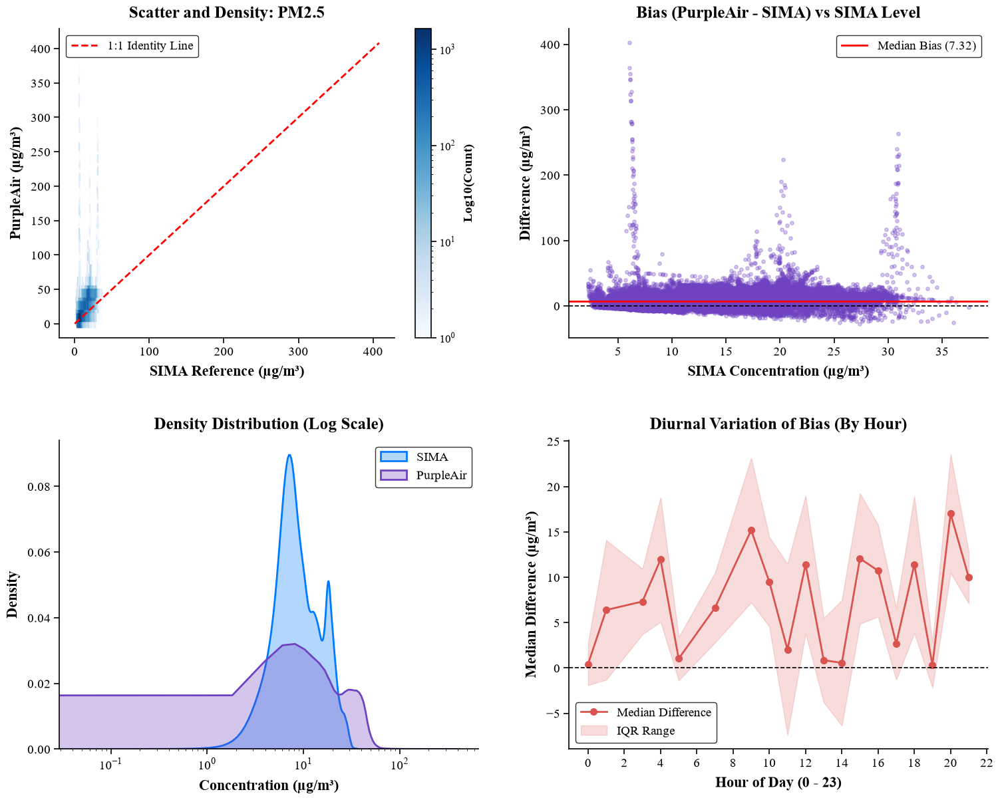


 STATISTICAL DIAGNOSTIC: PM10
Paired Records (n): 34,691
SIMA       -> Median: 37.06 µg/m³ | IQR: 22.63
PurpleAir  -> Median: 21.41 µg/m³ | IQR: 30.84
Difference -> Median Bias (PurpleAir - SIMA): -11.08 µg/m³

-- Correlation Assessment --
Pearson Correlation (Linearity): r = 0.461 (p-val: 0.00e+00)
Spearman Correlation (Monotonicity): r = 0.561 (p-val: 0.00e+00)
💡 Note: Significant non-linear relationship or extreme outlier bias detected.



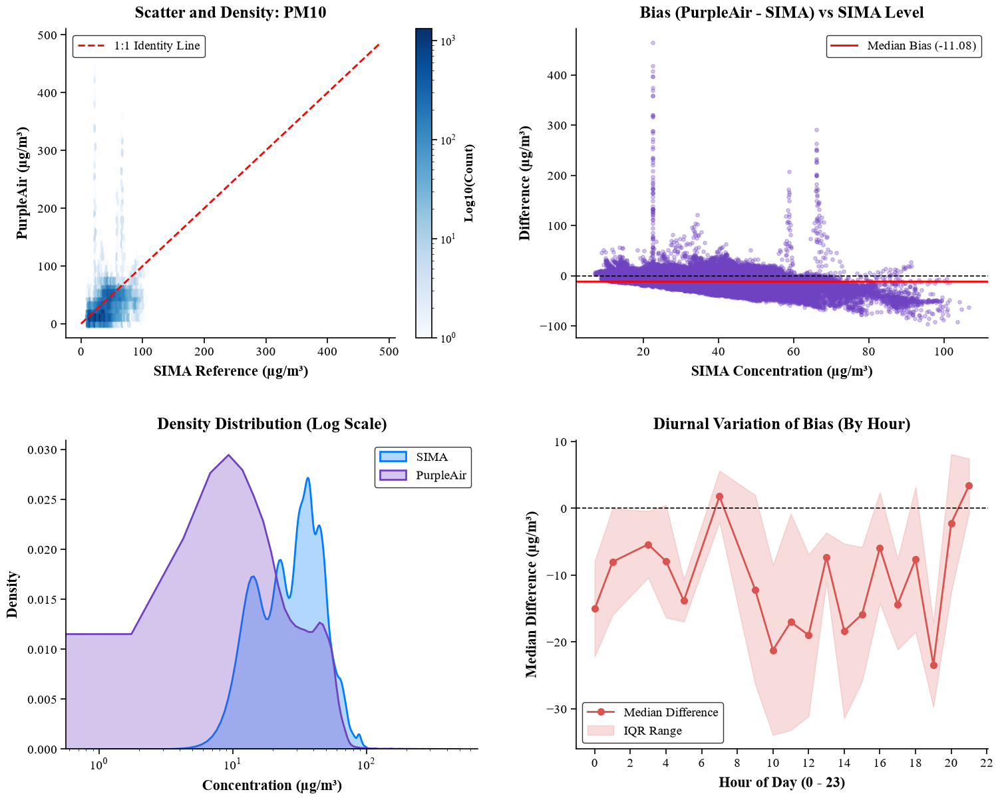

In [21]:
import numpy as np
import pandas as pd
import scipy.stats as stats
import matplotlib.pyplot as plt
import seaborn as sns

# Configure global matplotlib style for Publication Quality (Times New Roman, No Grid)
plt.rcParams.update({
    "font.family": "serif",
    "font.serif": ["Times New Roman"],
    "font.size": 14,
    "axes.labelsize": 16,
    "axes.titlesize": 18,
    "xtick.labelsize": 14,
    "ytick.labelsize": 14,
    "legend.fontsize": 14,
    "figure.titlesize": 20,
    "axes.grid": False  # Remove grid background
})

COLOR_PA = "#6f42c1"
COLOR_SIMA = "#007bff"
COLOR_DIF = "#d9534f"

def plot_english_clean_eda(df_pairs):
    for cont in ["PM2.5", "PM10"]:
        sub = df_pairs[df_pairs["contaminante"] == cont].copy()
        
        # -------------------------------------------------------------------------
        # 0. Statistical Console Outputs
        # -------------------------------------------------------------------------
        med_sima = sub["SIMA"].median()
        iqr_sima = sub["SIMA"].quantile(0.75) - sub["SIMA"].quantile(0.25)
        
        med_pa = sub["PurpleAir"].median()
        iqr_pa = sub["PurpleAir"].quantile(0.75) - sub["PurpleAir"].quantile(0.25)
        
        med_dif = sub["diferencia"].median()
        
        r_pearson, p_pearson = stats.pearsonr(sub["SIMA"], sub["PurpleAir"])
        r_spearman, p_spearman = stats.spearmanr(sub["SIMA"], sub["PurpleAir"])
        
        print("\n" + "=" * 50)
        print(f" STATISTICAL DIAGNOSTIC: {cont}")
        print("=" * 50)
        print(f"Paired Records (n): {len(sub):,}")
        print(f"SIMA       -> Median: {med_sima:.2f} µg/m³ | IQR: {iqr_sima:.2f}")
        print(f"PurpleAir  -> Median: {med_pa:.2f} µg/m³ | IQR: {iqr_pa:.2f}")
        print(f"Difference -> Median Bias (PurpleAir - SIMA): {med_dif:.2f} µg/m³")
        print("\n-- Correlation Assessment --")
        print(f"Pearson Correlation (Linearity): r = {r_pearson:.3f} (p-val: {p_pearson:.2e})")
        print(f"Spearman Correlation (Monotonicity): r = {r_spearman:.3f} (p-val: {p_spearman:.2e})")
        if r_spearman - r_pearson > 0.05:
            print("💡 Note: Significant non-linear relationship or extreme outlier bias detected.")
        print("=" * 50 + "\n")
        
        # -------------------------------------------------------------------------
        # 1. Figure setup: 2x2 grid, white background
        # -------------------------------------------------------------------------
        fig, axes = plt.subplots(2, 2, figsize=(16, 13), facecolor="white")
        fig.patch.set_facecolor("white")
        
        for ax in axes.flat:
            ax.set_facecolor("white")
            for spine in ax.spines.values():
                spine.set_color("black")
                spine.set_linewidth(1.2)

        # -------------------------------------------------------------------------
        # Hexbin Scatter Plot (Top-Left)
        # -------------------------------------------------------------------------
        hb = axes[0, 0].hexbin(sub["SIMA"], sub["PurpleAir"], gridsize=40, 
                               cmap="Blues", mincnt=1, bins='log')
        max_val = max(sub["SIMA"].max(), sub["PurpleAir"].max())
        axes[0, 0].plot([0, max_val], [0, max_val], 'r--', lw=2, label="1:1 Identity Line")
        axes[0, 0].set_title(f"Scatter and Density: {cont}", fontweight="bold", pad=12)
        axes[0, 0].set_xlabel("SIMA Reference (µg/m³)")
        axes[0, 0].set_ylabel("PurpleAir (µg/m³)")
        axes[0, 0].legend(loc="upper left", frameon=True, edgecolor="black")
        
        cb = fig.colorbar(hb, ax=axes[0, 0])
        cb.set_label("Log10(Count)", fontsize=14)
        cb.ax.tick_params(labelsize=12)

        # -------------------------------------------------------------------------
        # Bias Plot / Residuals (Top-Right)
        # -------------------------------------------------------------------------
        axes[0, 1].scatter(sub["SIMA"], sub["diferencia"], alpha=0.3, color=COLOR_PA, s=15)
        axes[0, 1].axhline(0, color="black", linestyle="--", lw=1.2)
        axes[0, 1].axhline(med_dif, color="red", linestyle="-", lw=2, 
                           label=f"Median Bias ({med_dif:.2f})")
        axes[0, 1].set_title(f"Bias (PurpleAir - SIMA) vs SIMA Level", fontweight="bold", pad=12)
        axes[0, 1].set_xlabel("SIMA Concentration (µg/m³)")
        axes[0, 1].set_ylabel("Difference (µg/m³)")
        axes[0, 1].legend(loc="upper right", frameon=True, edgecolor="black")

        # -------------------------------------------------------------------------
        # Log-scale Density Distribution (Bottom-Left)
        # -------------------------------------------------------------------------
        sns.kdeplot(sub["SIMA"], ax=axes[1, 0], color=COLOR_SIMA, label="SIMA", fill=True, alpha=0.3, lw=2)
        sns.kdeplot(sub["PurpleAir"], ax=axes[1, 0], color=COLOR_PA, label="PurpleAir", fill=True, alpha=0.3, lw=2)
        axes[1, 0].set_xscale("log")
        axes[1, 0].set_title("Density Distribution (Log Scale)", fontweight="bold", pad=12)
        axes[1, 0].set_xlabel("Concentration (µg/m³)")
        axes[1, 0].set_ylabel("Density")
        axes[1, 0].legend(loc="upper right", frameon=True, edgecolor="black")

        # -------------------------------------------------------------------------
        # Diurnal Pattern of Bias (Bottom-Right)
        # -------------------------------------------------------------------------
        perfil_hora = sub.groupby("hora")["diferencia"].agg(
            ["median", lambda x: x.quantile(0.75) - x.quantile(0.25)]
        )
        perfil_hora.columns = ["mediana", "iqr"]

        axes[1, 1].plot(perfil_hora.index, perfil_hora["mediana"], marker="o", ms=7, 
                        color=COLOR_DIF, lw=2, label="Median Difference")
        axes[1, 1].fill_between(perfil_hora.index, 
                                perfil_hora["mediana"] - perfil_hora["iqr"]/2, 
                                perfil_hora["mediana"] + perfil_hora["iqr"]/2, 
                                color=COLOR_DIF, alpha=0.2, label="IQR Range")
        axes[1, 1].axhline(0, color="black", linestyle="--", lw=1.2)
        axes[1, 1].set_title("Diurnal Variation of Bias (By Hour)", fontweight="bold", pad=12)
        axes[1, 1].set_xlabel("Hour of Day (0 - 23)")
        axes[1, 1].set_ylabel("Median Difference (µg/m³)")
        axes[1, 1].set_xticks(range(0, 24, 2))
        axes[1, 1].legend(loc="lower left", frameon=True, edgecolor="black")

        plt.tight_layout(pad=3.0)
        plt.show()

# Run script
plot_english_clean_eda(df_pares)

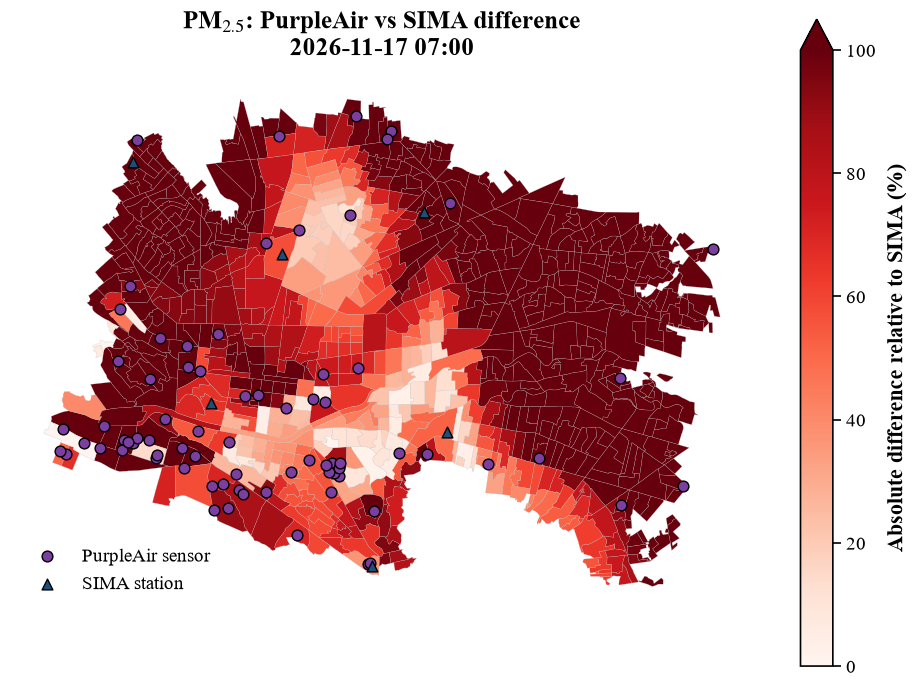

,AGEBs,%
Zona,,
Confiable (< 25 %),58,7.3
Moderada (25–50 %),89,11.3
Alta incertidumbre (≥ 50 %),643,81.4


AGEBs con mayor diferencia en el periodo:


,diferencia_pct_abs
cvegeo,
1901900010100,884.5
1901900010350,565.6
1903900012400,498.4
1903900012519,455.5
1903900013324,448.8
1903900013998,441.1
1903900012576,439.6
1903900012523,427.5
1903900013339,416.4


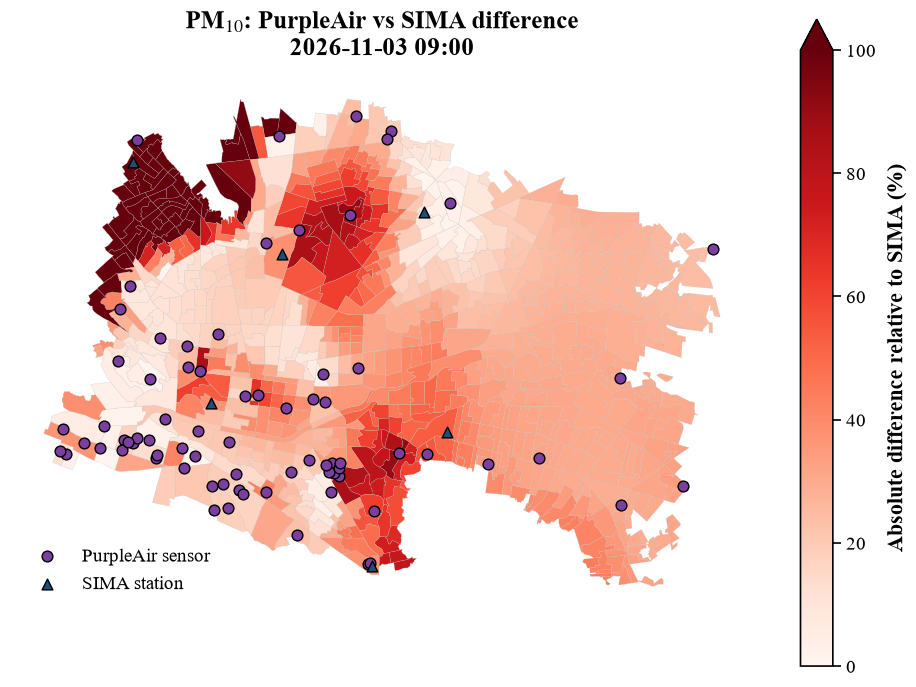

,AGEBs,%
Zona,,
Confiable (< 25 %),229,29.0
Moderada (25–50 %),416,52.7
Alta incertidumbre (≥ 50 %),145,18.4


AGEBs con mayor diferencia en el periodo:


,diferencia_pct_abs
cvegeo,
1903900012400,440.7
1903900012519,399.0
1903900012576,382.8
1903900013998,378.0
1903900013324,377.9
1903900012523,351.7
1903900010033,348.2
1903900013339,341.7
1903900014002,341.3


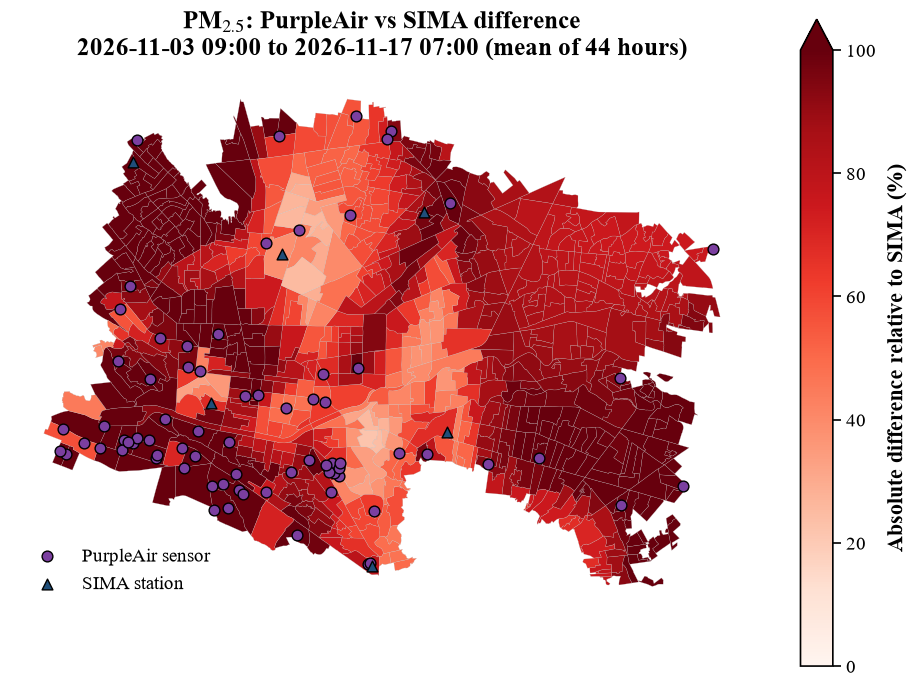

,AGEBs,%
Zona,,
Confiable (< 25 %),2,0.3
Moderada (25–50 %),79,10.0
Alta incertidumbre (≥ 50 %),709,89.7


AGEBs con mayor diferencia en el periodo:


,diferencia_pct_abs
cvegeo,
1901900010100,431.6
1903900012400,357.3
1903900012519,327.5
1903900013324,317.0
1903900013998,313.2
1903900012576,312.2
1901900010350,304.0
1903900012523,301.6
1903900013339,290.8


GIF guardado en figuras\animacion_diferencia_PM25_pct.gif


In [22]:
from matplotlib import animation
from matplotlib.cm import ScalarMappable
from matplotlib.colors import Normalize
from IPython.display import HTML

METRICA = "pct"   # "pct": |PA − SIMA| / SIMA × 100   ·   "abs": |PA − SIMA| en µg/m³
ESCALA_MAX = {"pct": 100, "abs": None}   # tope de la escala de color; None = percentil 95 de los datos
NIVELES_PCT = (25, 50)                    # % para resumir zonas: confiable < 25 ≤ moderada < 50 ≤ alta
plt.rcParams["animation.embed_limit"] = 100  # MB, para animaciones largas dentro del notebook

if agebs_gdf is None:
    raise RuntimeError("Este bloque necesita geopandas y el SHP de AGEBs (bloque 2).")

pares["diferencia_pct_abs"] = pares["diferencia_pct"].abs()
COLUMNA = {"pct": "diferencia_pct_abs", "abs": "diferencia_abs"}
ETIQUETA_METRICA = {"pct": "Absolute difference relative to SIMA (%)",
                    "abs": r"Absolute difference |PA $-$ SIMA| ($\mu$g/m$^3$)"}
MAPA_BASE = agebs_gdf.loc[agebs_gdf["cvegeo"].isin(AGEBS_COMUNES), ["cvegeo", "geometry"]].reset_index(drop=True)
ESTILO_SIN_DATO = {"color": "#EEEEEE", "edgecolor": "#BBBBBB", "linewidth": 0.15}


def tope_color(contaminante, metrica):
    if ESCALA_MAX[metrica] is not None:
        return ESCALA_MAX[metrica]
    return float(pares.loc[pares["contaminante"] == contaminante, COLUMNA[metrica]].quantile(0.95))


def diferencia_por_ageb(contaminante, inicio, fin, metrica):
    """Diferencia media de cada AGEB entre inicio y fin (inclusive)."""
    p = pares[(pares["contaminante"] == contaminante) & pares["timestamp"].between(inicio, fin)]
    return p.groupby("cvegeo")[COLUMNA[metrica]].mean(), sorted(p["timestamp"].unique())


def dibujar_mapa(ax, valores, vmax, titulo):
    ax.clear()
    MAPA_BASE.assign(valor=MAPA_BASE["cvegeo"].map(valores)).plot(
        ax=ax, column="valor", cmap="Reds", vmin=0, vmax=vmax,
        edgecolor="#BBBBBB", linewidth=0.15, missing_kwds=ESTILO_SIN_DATO)
    if not ubicaciones.empty:
        for red, marcador in (("PurpleAir", "o"), ("SIMA", "^")):
            u = ubicaciones[(ubicaciones["red"] == red) & ubicaciones["en_cobertura"]]
            ax.scatter(u["lon"], u["lat"], marker=marcador, s=60, color=COLORES[red], edgecolor="black",
                       zorder=5, label=f"{red} {'sensor' if red == 'PurpleAir' else 'station'}")
        ax.legend(loc="lower left")
    ax.set_title(titulo)
    ax.set_axis_off()


def barra_color(fig, ax, vmax, metrica):
    fig.colorbar(ScalarMappable(Normalize(0, vmax), cmap="Reds"), ax=ax, shrink=0.7,
                 label=ETIQUETA_METRICA[metrica], extend="max")


def a_fecha(valor, por_defecto):
    return pd.Timestamp(valor) if valor is not None else por_defecto


def mapa_diferencia(contaminante="PM2.5", inicio=None, fin=None, metrica=METRICA, archivo=None):
    """Mapa de la diferencia por AGEB en una hora (solo inicio) o en una ventana (inicio y fin).
    Sin fechas, usa la última hora con dato en ambas redes."""
    inicio = a_fecha(inicio, HORAS_COMUNES[-1])
    fin = a_fecha(fin, inicio)
    valores, horas = diferencia_por_ageb(contaminante, inicio, fin, metrica)
    if valores.empty:
        cercanas = sorted(HORAS_COMUNES, key=lambda h: abs(h - inicio))[:5]
        print(f"No hay lecturas emparejadas entre {inicio} y {fin}. Horas disponibles más cercanas:")
        print(", ".join(f"{h:%Y-%m-%d %H:%M}" for h in sorted(cercanas)))
        return None

    if len(horas) == 1:
        periodo = f"{horas[0]:%Y-%m-%d %H:%M}"
    else:
        periodo = f"{horas[0]:%Y-%m-%d %H:%M} to {horas[-1]:%Y-%m-%d %H:%M} (mean of {len(horas)} hours)"
    vmax = tope_color(contaminante, metrica)
    fig, ax = plt.subplots(figsize=(12, 12))
    dibujar_mapa(ax, valores, vmax, f"{ETIQUETA[contaminante]}: PurpleAir vs SIMA difference\n{periodo}")
    barra_color(fig, ax, vmax, metrica)
    if archivo:
        guardar(fig, archivo)
    plt.show()

    # Resumen de zonas por nivel de diferencia relativa
    relativa = (pares[(pares["contaminante"] == contaminante) & pares["timestamp"].between(inicio, fin)]
                .groupby("cvegeo")["diferencia_pct_abs"].mean())
    zonas = pd.cut(relativa, [-np.inf, NIVELES_PCT[0], NIVELES_PCT[1], np.inf], right=False,
                   labels=[f"Confiable (< {NIVELES_PCT[0]} %)", f"Moderada ({NIVELES_PCT[0]}–{NIVELES_PCT[1]} %)",
                           f"Alta incertidumbre (≥ {NIVELES_PCT[1]} %)"])
    resumen = zonas.value_counts(sort=False).rename_axis("Zona").to_frame("AGEBs")
    resumen["%"] = (100 * resumen["AGEBs"] / resumen["AGEBs"].sum()).round(1)
    display(resumen)
    print("AGEBs con mayor diferencia en el periodo:")
    display(valores.sort_values(ascending=False).head(10).round(1).to_frame(COLUMNA[metrica]))
    return valores


def animar_diferencia(contaminante="PM2.5", inicio=None, fin=None, metrica=METRICA,
                      ms_por_cuadro=800, guardar_gif=True):
    """Animación hora por hora de la diferencia por AGEB, con escala de color fija."""
    inicio = a_fecha(inicio, HORAS_COMUNES[0])
    fin = a_fecha(fin, HORAS_COMUNES[-1])
    p = pares[(pares["contaminante"] == contaminante) & pares["timestamp"].between(inicio, fin)]
    por_hora = {h: g.set_index("cvegeo")[COLUMNA[metrica]] for h, g in p.groupby("timestamp")}
    horas = sorted(por_hora)
    if not horas:
        print("No hay horas con dato en ambas redes en ese periodo.")
        return None

    vmax = tope_color(contaminante, metrica)
    fig, ax = plt.subplots(figsize=(12, 12))
    barra_color(fig, ax, vmax, metrica)

    def cuadro(i):
        h = horas[i]
        dibujar_mapa(ax, por_hora[h], vmax,
                     f"{ETIQUETA[contaminante]}: PurpleAir vs SIMA difference\n{h:%Y-%m-%d %H:%M} "
                     f"(frame {i + 1}/{len(horas)})")

    anim = animation.FuncAnimation(fig, cuadro, frames=len(horas), interval=ms_por_cuadro)
    if guardar_gif:
        DIR_FIGURAS.mkdir(exist_ok=True)
        ruta = DIR_FIGURAS / f"animacion_diferencia_{contaminante.replace('.', '')}_{metrica}.gif"
        anim.save(ruta, writer=animation.PillowWriter(fps=1000 / ms_por_cuadro), dpi=80)
        print(f"GIF guardado en {ruta}")
    plt.close(fig)
    return HTML(anim.to_jshtml())


# Ejemplos (cada línea en su propia celda si se prefiere):
mapa_diferencia("PM2.5")                                                      # última hora en común
mapa_diferencia("PM10", inicio="2026-11-03 09:00")                            # una hora concreta
mapa_diferencia("PM2.5", inicio=INICIO_COMUN, fin=FIN_COMUN, archivo="mapa_dif_pm25_periodo")  # todo el periodo
animar_diferencia("PM2.5")                                                    # animación de todas las horas

### Per-AGEB Correlation and Confidence Assessment of the Interpolated PurpleAir Estimate

In [23]:
# =============================================================================
# BLOQUE 2 · Métricas por AGEB, clases de confianza y descomposición de la correlación
# =============================================================================
N_MIN = 8
CRITERIOS = {"r_ci_alta": 0.50, "nmb_alta": 25, "r_media": 0.50, "q_media": 0.05, "nmb_media": 50}
Z95 = stats.norm.ppf(0.975)


def autocorr_lag1(serie):
    """Autocorrelación a 1 h usando solo pares de horas realmente consecutivas."""
    x = serie.to_numpy(float) - serie.mean()
    var = (x ** 2).mean()
    consecutivas = serie.index.to_series().diff().eq(pd.Timedelta(hours=1)).to_numpy()[1:]
    if var == 0 or consecutivas.sum() < 3:
        return 0.0
    return float((x[1:] * x[:-1])[consecutivas].mean() / var)


def n_efectivo(sx, sy):
    """n efectivo de la correlación entre dos series autocorrelacionadas (Bretherton et al., 1999)."""
    prod = float(np.clip(autocorr_lag1(sx) * autocorr_lag1(sy), -0.9, 0.9))
    return float(np.clip(len(sx) * (1 - prod) / (1 + prod), 3, len(sx)))


def metricas_ageb(g):
    g = g.sort_values("timestamp").set_index("timestamp")
    x, y = g["SIMA"], g["PurpleAir"]
    d = y - x
    n = len(g)
    rmse = np.sqrt((d ** 2).mean())
    m = {"n": n, "mean_SIMA": x.mean(), "mean_PA": y.mean(), "MBE": d.mean(), "MAE": d.abs().mean(),
         "RMSE": rmse,
         "NMB_pct": 100 * d.sum() / x.sum() if x.sum() > 0 else np.nan,
         "NRMSE_pct": 100 * rmse / x.mean() if x.mean() > 0 else np.nan}
    vacio = dict.fromkeys(["r", "rho", "n_eff", "r_ci_lo", "r_ci_hi", "p", "slope", "intercept"], np.nan)
    if n < 4 or x.std() == 0 or y.std() == 0:
        return pd.Series({**m, **vacio})
    r = float(np.clip(stats.pearsonr(x, y)[0], -0.9999, 0.9999))
    ne = n_efectivo(x, y)
    se = 1 / np.sqrt(ne - 3) if ne > 3 else np.inf
    t = r * np.sqrt((ne - 2) / (1 - r ** 2))
    slope, intercept = np.polyfit(x, y, 1)
    return pd.Series({**m, "r": r, "rho": stats.spearmanr(x, y)[0], "n_eff": ne,
                      "r_ci_lo": np.tanh(np.arctanh(r) - Z95 * se), "r_ci_hi": np.tanh(np.arctanh(r) + Z95 * se),
                      "p": 2 * stats.t.sf(abs(t), ne - 2), "slope": slope, "intercept": intercept})


def clasificar(fila, c=CRITERIOS):
    if fila["n"] < N_MIN or pd.isna(fila["r"]):
        return "Insufficient"
    if fila["r_ci_lo"] >= c["r_ci_alta"] and abs(fila["NMB_pct"]) <= c["nmb_alta"]:
        return "High"
    if fila["r"] >= c["r_media"] and fila["q"] < c["q_media"] and abs(fila["NMB_pct"]) <= c["nmb_media"]:
        return "Medium"
    return "Low"


def confianza_por_ageb(pares):
    tablas = []
    for cont, sub in pares.groupby("contaminante"):
        t = sub.groupby("cvegeo")[["timestamp", "SIMA", "PurpleAir"]].apply(metricas_ageb).reset_index()
        t.insert(1, "contaminante", cont)
        validos = t["p"].notna()
        t["q"] = np.nan
        t.loc[validos, "q"] = stats.false_discovery_control(t.loc[validos, "p"])
        t["confidence"] = pd.Categorical(t.apply(clasificar, axis=1), categories=CLASES, ordered=True)
        tablas.append(t)
    return pd.concat(tablas, ignore_index=True)


def correlacion_espacial_por_hora(pares):
    """r entre AGEBs en cada hora: ¿el mapa ordena bien las zonas?"""
    filas = []
    for (cont, h), g in pares.groupby(["contaminante", "timestamp"]):
        if len(g) >= 10 and g["SIMA"].std() > 0 and g["PurpleAir"].std() > 0:
            filas.append({"contaminante": cont, "timestamp": h,
                          "r_spatial": stats.pearsonr(g["SIMA"], g["PurpleAir"])[0]})
    return pd.DataFrame(filas)


confianza = confianza_por_ageb(pares)
espacial = correlacion_espacial_por_hora(pares)

for cont in CONTAMINANTES:
    t = confianza[confianza["contaminante"] == cont]
    s = pares[pares["contaminante"] == cont]
    e = espacial[espacial["contaminante"] == cont]
    conteo = t["confidence"].value_counts().reindex(CLASES, fill_value=0)

    banner(f"PER-AGEB CONFIDENCE DIAGNOSTIC: {cont}")
    print(f"AGEBs evaluated: {len(t):,} | Hours per AGEB (median): {t['n'].median():.0f} | "
          f"Effective n (median): {t['n_eff'].median():.1f}")
    print("\n-- Correlation Decomposition --")
    print(f"Pooled Pearson r (all pairs)        : {stats.pearsonr(s['SIMA'], s['PurpleAir'])[0]:.3f}")
    print(f"Temporal r (median across AGEBs)    : {t['r'].median():.3f}  "
          f"[IQR {t['r'].quantile(0.25):.3f} – {t['r'].quantile(0.75):.3f}]")
    print(f"Spatial r (median across hours)     : {e['r_spatial'].median():.3f}  "
          f"[min {e['r_spatial'].min():.3f} – max {e['r_spatial'].max():.3f}]")
    print(f"AGEBs with significant r (q < 0.05) : {100 * (t['q'] < 0.05).mean():.1f} %")
    print(f"Median 95% CI width of r            : {(t['r_ci_hi'] - t['r_ci_lo']).median():.3f}")
    print("\n-- Bias and Error (median across AGEBs) --")
    print(f"MBE: {t['MBE'].median():.2f} µg/m³ | NMB: {t['NMB_pct'].median():.1f} % | "
          f"RMSE: {t['RMSE'].median():.2f} µg/m³ | Slope: {t['slope'].median():.2f}")
    print("\n-- Confidence Classes --")
    for clase in CLASES:
        print(f"{clase:<13}: {conteo[clase]:>5,} AGEBs ({100 * conteo[clase] / len(t):5.1f} %)")
    cierre()

DIR_RESULTADOS.mkdir(exist_ok=True)
confianza.to_csv(DIR_RESULTADOS / "confianza_por_ageb.csv", index=False, encoding="utf-8-sig")
print(f"Full table saved to {DIR_RESULTADOS / 'confianza_por_ageb.csv'}")


C:\Users\betor\AppData\Local\Temp\ipykernel_37012\3469028064.py:38: ConstantInputWarning: An input array is constant; the correlation coefficient is not defined.
  r = float(np.clip(stats.pearsonr(x, y)[0], -0.9999, 0.9999))
C:\Users\betor\AppData\Local\Temp\ipykernel_37012\3469028064.py:43: ConstantInputWarning: An input array is constant; the correlation coefficient is not defined.
  return pd.Series({**m, "r": r, "rho": stats.spearmanr(x, y)[0], "n_eff": ne,
C:\Users\betor\AppData\Local\Temp\ipykernel_37012\3469028064.py:38: ConstantInputWarning: An input array is constant; the correlation coefficient is not defined.
  r = float(np.clip(stats.pearsonr(x, y)[0], -0.9999, 0.9999))
C:\Users\betor\AppData\Local\Temp\ipykernel_37012\3469028064.py:43: ConstantInputWarning: An input array is constant; the correlation coefficient is not defined.
  return pd.Series({**m, "r": r, "rho": stats.spearmanr(x, y)[0], "n_eff": ne,
C:\Users\betor\AppData\Local\Temp\ipykernel_37012\3469028064.py:38: 


 PER-AGEB CONFIDENCE DIAGNOSTIC: PM2.5
AGEBs evaluated: 790 | Hours per AGEB (median): 44 | Effective n (median): 44.0

-- Correlation Decomposition --
Pooled Pearson r (all pairs)        : 0.591
Temporal r (median across AGEBs)    : 0.793  [IQR 0.722 – 0.833]
Spatial r (median across hours)     : 0.167  [min -0.497 – max 0.724]
AGEBs with significant r (q < 0.05) : 97.5 %
Median 95% CI width of r            : 0.234

-- Bias and Error (median across AGEBs) --
MBE: 9.58 µg/m³ | NMB: 76.8 % | RMSE: 13.44 µg/m³ | Slope: 1.82

-- Confidence Classes --
High         :    46 AGEBs (  5.8 %)
Medium       :   113 AGEBs ( 14.3 %)
Low          :   625 AGEBs ( 79.1 %)
Insufficient :     6 AGEBs (  0.8 %)


 PER-AGEB CONFIDENCE DIAGNOSTIC: PM10
AGEBs evaluated: 790 | Hours per AGEB (median): 44 | Effective n (median): 44.0

-- Correlation Decomposition --
Pooled Pearson r (all pairs)        : 0.461
Temporal r (median across AGEBs)    : 0.595  [IQR 0.516 – 0.647]
Spatial r (median across hours)    

C:\Users\betor\AppData\Local\Temp\ipykernel_37012\3469028064.py:77: ConstantInputWarning: An input array is constant; the correlation coefficient is not defined.
  "r_spatial": stats.pearsonr(g["SIMA"], g["PurpleAir"])[0]})


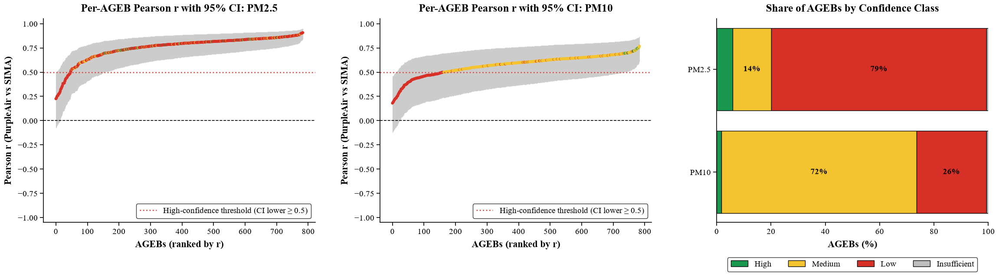

In [24]:
# =============================================================================
# BLOQUE 3 · Distribución de r por AGEB con su IC 95 % y proporción de clases
# =============================================================================
fig, axes = nueva_figura(1, 3, (24, 7.5))

for ax, cont in zip(axes[0, :2], CONTAMINANTES):
    t = (confianza[(confianza["contaminante"] == cont) & confianza["r"].notna()]
         .sort_values("r").reset_index(drop=True))
    ax.vlines(t.index, t["r_ci_lo"], t["r_ci_hi"], color="#CCCCCC", lw=0.8, zorder=1)
    ax.scatter(t.index, t["r"], c=t["confidence"].astype(str).map(COLOR_CLASE), s=14, zorder=2)
    ax.axhline(0, color="black", linestyle="--", lw=1.2)
    ax.axhline(CRITERIOS["r_ci_alta"], color=COLOR_DIF, linestyle=":", lw=2,
               label=f"High-confidence threshold (CI lower ≥ {CRITERIOS['r_ci_alta']})")
    ax.set_title(f"Per-AGEB Pearson r with 95% CI: {cont}", fontweight="bold", pad=12)
    ax.set_xlabel("AGEBs (ranked by r)")
    ax.set_ylabel("Pearson r (PurpleAir vs SIMA)")
    ax.set_ylim(-1.05, 1.05)
    leyenda(ax, loc="lower right")

ax = axes[0, 2]
pct = (confianza.groupby(["contaminante", "confidence"], observed=False).size()
       .unstack("confidence").reindex(index=CONTAMINANTES, columns=CLASES, fill_value=0))
pct = 100 * pct.div(pct.sum(axis=1), axis=0)
izquierda = np.zeros(len(pct))
for clase in CLASES:
    ax.barh(pct.index, pct[clase], left=izquierda, color=COLOR_CLASE[clase], edgecolor="black", label=clase)
    for i, (v, x0) in enumerate(zip(pct[clase], izquierda)):
        if v >= 6:
            ax.text(x0 + v / 2, i, f"{v:.0f}%", ha="center", va="center", fontsize=14, fontweight="bold")
    izquierda += pct[clase].to_numpy()
ax.set_xlim(0, 100)
ax.set_title("Share of AGEBs by Confidence Class", fontweight="bold", pad=12)
ax.set_xlabel("AGEBs (%)")
ax.invert_yaxis()
leyenda(ax, loc="upper center", bbox_to_anchor=(0.5, -0.15), ncol=4)

plt.tight_layout(pad=3.0)
guardar(fig, "r_por_ageb_ic95")
plt.show()


 CONFIDENCE DRIVERS: PM2.5
-- Spearman rho between fit metric and driver (p-value) --
r        -> dist_PurpleAir_km: +0.126 (3.9e-04) | dist_SIMA_km: +0.120 (7.8e-04) | n_sensors_mean: -0.063 (8.0e-02)
RMSE     -> dist_PurpleAir_km: -0.114 (1.3e-03) | dist_SIMA_km: +0.100 (4.8e-03) | n_sensors_mean: +0.088 (1.4e-02)
abs_NMB  -> dist_PurpleAir_km: +0.036 (3.1e-01) | dist_SIMA_km: +0.156 (1.0e-05) | n_sensors_mean: +0.029 (4.2e-01)

-- Performance by Distance to Nearest PurpleAir Sensor --
         AGEBs  r_median  RMSE_median  pct_High_Medium
band_PA                                               
0–1 km     258      0.79        14.55            22.09
1–2 km     269      0.78        13.35            25.65
2–3 km     148      0.78        13.45            14.19
3–5 km     106      0.83        12.39            11.32
≥ 5 km       9      0.84        11.54             0.00


 CONFIDENCE DRIVERS: PM10
-- Spearman rho between fit metric and driver (p-value) --
r        -> dist_PurpleAir_km: -0.

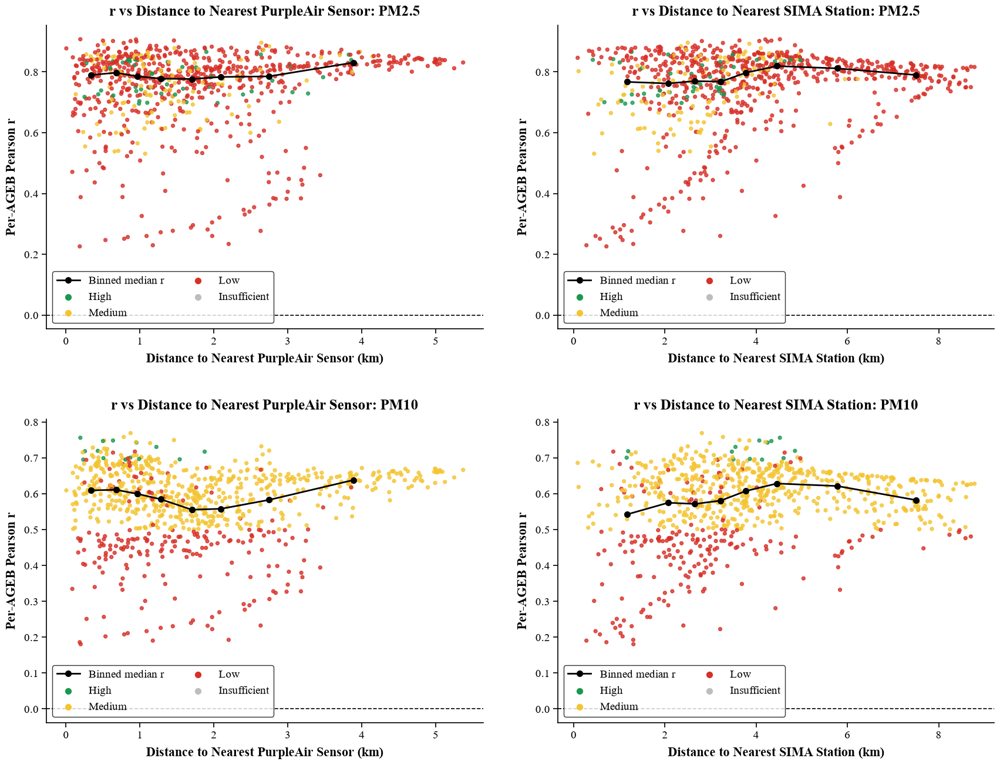

In [25]:
# =============================================================================
# BLOQUE 4 · ¿De qué depende la confianza? Distancia al sensor / estación más cercanos
# =============================================================================
from scipy.spatial import cKDTree

R_TIERRA = 6_371_000.0
BANDAS_KM = [0, 1, 2, 3, 5, np.inf]


def a_metros(lon, lat, lat0):
    """Proyección equirectangular local (error despreciable a escala metropolitana)."""
    return np.column_stack([np.radians(lon) * R_TIERRA * np.cos(np.radians(lat0)), np.radians(lat) * R_TIERRA])


def centroides_agebs():
    if agebs_gdf is None:
        return None
    c = agebs_gdf.loc[agebs_gdf["cvegeo"].isin(AGEBS_COMUNES)].to_crs("EPSG:32614").centroid.to_crs("EPSG:4326")
    return pd.DataFrame({"cvegeo": agebs_gdf.loc[c.index, "cvegeo"].values, "lon": c.x.values, "lat": c.y.values})


def distancias_a_red(centroides, ubicaciones):
    lat0 = centroides["lat"].mean()
    xy = a_metros(centroides["lon"], centroides["lat"], lat0)
    salida = centroides[["cvegeo"]].copy()
    for red in ("PurpleAir", "SIMA"):
        u = ubicaciones[ubicaciones["red"] == red].dropna(subset=["lon", "lat"])
        if not u.empty:
            d, _ = cKDTree(a_metros(u["lon"], u["lat"], lat0)).query(xy, k=1)
            salida[f"dist_{red}_km"] = d / 1000
    return salida


CENTROIDES = centroides_agebs()
if CENTROIDES is None or ubicaciones.empty:
    print("Geopandas/SHP or sensor layers not available: distance analysis skipped.")
else:
    dist = distancias_a_red(CENTROIDES, ubicaciones)
    confianza = confianza.drop(columns=[c for c in dist.columns if c != "cvegeo"], errors="ignore")
    confianza = confianza.merge(dist, on="cvegeo", how="left")
    if "n_sensores" in pa.columns:
        confianza = confianza.drop(columns="n_sensors_mean", errors="ignore").merge(
            pa.groupby("cvegeo")["n_sensores"].mean().rename("n_sensors_mean"), on="cvegeo", how="left")
    confianza["band_PA"] = pd.cut(confianza["dist_PurpleAir_km"], BANDAS_KM, right=False,
                                  labels=[f"{a:g}–{b:g} km" if np.isfinite(b) else f"≥ {a:g} km"
                                          for a, b in zip(BANDAS_KM[:-1], BANDAS_KM[1:])])
    determinantes = [c for c in ("dist_PurpleAir_km", "dist_SIMA_km", "n_sensors_mean") if c in confianza]

    for cont in CONTAMINANTES:
        t = confianza[confianza["contaminante"] == cont].assign(abs_NMB=lambda d: d["NMB_pct"].abs())
        banner(f"CONFIDENCE DRIVERS: {cont}")
        print("-- Spearman rho between fit metric and driver (p-value) --")
        for metrica in ("r", "RMSE", "abs_NMB"):
            celdas_txt = []
            for det in determinantes:
                ok = t[[metrica, det]].dropna()
                rho, p = stats.spearmanr(ok[metrica], ok[det])
                celdas_txt.append(f"{det}: {rho:+.3f} ({p:.1e})")
            print(f"{metrica:<8} -> " + " | ".join(celdas_txt))
        print("\n-- Performance by Distance to Nearest PurpleAir Sensor --")
        por_banda = (t.groupby("band_PA", observed=True)
                     .agg(AGEBs=("cvegeo", "size"), r_median=("r", "median"), RMSE_median=("RMSE", "median"),
                          pct_High_Medium=("confidence", lambda s: 100 * s.isin(["High", "Medium"]).mean())))
        tabla(por_banda, 2)
        cierre()

    fig, axes = nueva_figura(len(CONTAMINANTES), 2, (18, 7 * len(CONTAMINANTES)))
    for i, cont in enumerate(CONTAMINANTES):
        t = confianza[confianza["contaminante"] == cont]
        for j, red in enumerate(("PurpleAir", "SIMA")):
            ax, col = axes[i, j], f"dist_{red}_km"
            if col not in t:
                ax.set_visible(False)
                continue
            ax.scatter(t[col], t["r"], c=t["confidence"].astype(str).map(COLOR_CLASE), s=18, alpha=0.8)
            perfil = t.groupby(pd.qcut(t[col], 8, duplicates="drop"), observed=True).agg(
                d=(col, "median"), r=("r", "median"))
            ax.plot(perfil["d"], perfil["r"], color="black", marker="o", ms=7, lw=2, label="Binned median r")
            ax.axhline(0, color="black", linestyle="--", lw=1.2)
            tipo = "Sensor" if red == "PurpleAir" else "Station"
            ax.set_title(f"r vs Distance to Nearest {red} {tipo}: {cont}", fontweight="bold", pad=12)
            ax.set_xlabel(f"Distance to Nearest {red} {tipo} (km)")
            ax.set_ylabel("Per-AGEB Pearson r")
            for clase in CLASES:
                ax.scatter([], [], c=COLOR_CLASE[clase], s=50, label=clase)
            leyenda(ax, loc="lower left", ncol=2)
    plt.tight_layout(pad=3.0)
    guardar(fig, "r_vs_distancia")
    plt.show()


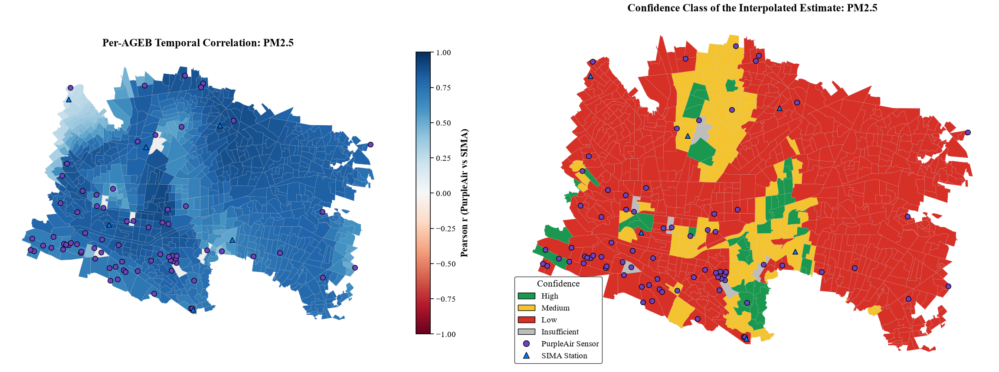

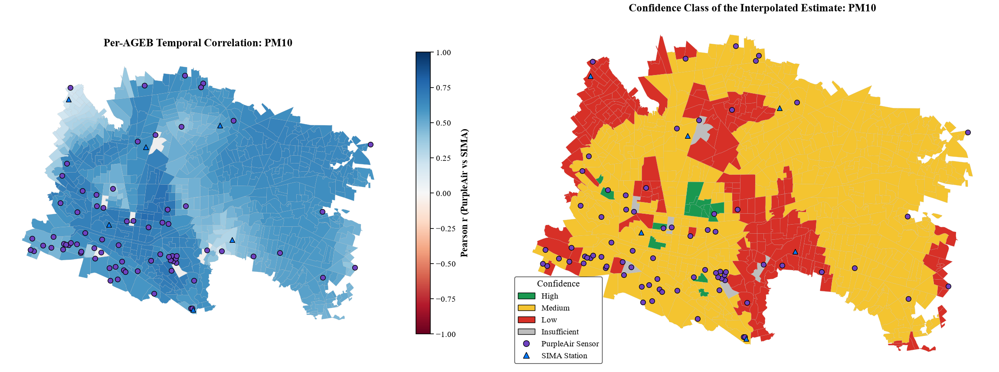

In [26]:
# =============================================================================
# BLOQUE 5 · Mapas: correlación temporal por AGEB y clase de confianza
# =============================================================================
from matplotlib.patches import Patch
from matplotlib.lines import Line2D


def mapa_confianza(contaminante="PM2.5", archivo=None):
    if agebs_gdf is None:
        print("Geopandas and the AGEB shapefile are required for the maps.")
        return
    t = confianza[confianza["contaminante"] == contaminante].set_index("cvegeo")
    base = MAPA_BASE.assign(r=MAPA_BASE["cvegeo"].map(t["r"]),
                            clase=MAPA_BASE["cvegeo"].map(t["confidence"].astype(str)))
    fig, axes = nueva_figura(1, 2, (24, 12))
    base.plot(ax=axes[0, 0], column="r", cmap="RdBu", vmin=-1, vmax=1, edgecolor="#BBBBBB", linewidth=0.15,
              missing_kwds=ESTILO_SIN_DATO, legend=True,
              legend_kwds={"shrink": 0.6, "label": "Pearson r (PurpleAir vs SIMA)"})
    axes[0, 0].set_title(f"Per-AGEB Temporal Correlation: {contaminante}", fontweight="bold", pad=12)
    base.plot(ax=axes[0, 1], color=base["clase"].map(COLOR_CLASE).fillna("#EEEEEE"),
              edgecolor="#BBBBBB", linewidth=0.15)
    axes[0, 1].set_title(f"Confidence Class of the Interpolated Estimate: {contaminante}", fontweight="bold", pad=12)
    for ax in axes.flat:
        for red, marcador in (("PurpleAir", "o"), ("SIMA", "^")):
            u = ubicaciones[(ubicaciones["red"] == red) & ubicaciones["cvegeo"].isin(AGEBS_COMUNES)]
            ax.scatter(u["lon"], u["lat"], marker=marcador, s=70, color=COLOR_PA if red == "PurpleAir" else COLOR_SIMA,
                       edgecolor="black", zorder=5)
        ax.set_axis_off()
    handles = [Patch(facecolor=COLOR_CLASE[c], edgecolor="black", label=c) for c in CLASES]
    handles += [Line2D([], [], marker="o", ls="", color=COLOR_PA, mec="black", ms=10, label="PurpleAir Sensor"),
                Line2D([], [], marker="^", ls="", color=COLOR_SIMA, mec="black", ms=10, label="SIMA Station")]
    axes[0, 1].legend(handles=handles, loc="lower left", title="Confidence", frameon=True, edgecolor="black")
    plt.tight_layout(pad=3.0)
    if archivo:
        guardar(fig, archivo)
    plt.show()


for cont in CONTAMINANTES:
    mapa_confianza(cont, archivo=f"mapa_confianza_{cont.replace('.', '')}")

In [30]:
# =============================================================================
# BLOQUE 6 · Autocorrelación espacial de la confianza (I de Moran, k-NN, permutaciones)
# =============================================================================
def moran_i(valores, xy, k=8, permutaciones=999, semilla=0):
    z = valores - valores.mean()
    _, idx = cKDTree(xy).query(xy, k=k + 1)
    vecinos = idx[:, 1:]
    i_obs = (z * z[vecinos].mean(axis=1)).sum() / (z ** 2).sum()
    rng = np.random.default_rng(semilla)
    sim = np.array([(zp * zp[vecinos].mean(axis=1)).sum() / (zp ** 2).sum()
                    for zp in (rng.permutation(z) for _ in range(permutaciones))])
    p = (1 + (np.abs(sim - sim.mean()) >= abs(i_obs - sim.mean())).sum()) / (permutaciones + 1)
    return i_obs, -1 / (len(z) - 1), p


if CENTROIDES is None:
    print("Centroids not available: Moran's I skipped.")
else:
    banner("SPATIAL AUTOCORRELATION OF CONFIDENCE (MORAN'S I, k = 8)")
    for cont in CONTAMINANTES:
        t = confianza[(confianza["contaminante"] == cont) & confianza["r"].notna()].merge(CENTROIDES, on="cvegeo")
        xy = a_metros(t["lon"], t["lat"], t["lat"].mean())
        for metrica in ("r", "RMSE"):
            i_obs, esperado, p = moran_i(t[metrica].to_numpy(float), xy)
            veredicto = "Clustered" if (i_obs > esperado and p < 0.05) else "No clear clustering"
            print(f"{cont:<6} {metrica:<5} -> I = {i_obs:+.4f} | E[I] = {esperado:+.4f} | p = {p:.3f} | {veredicto}")
    cierre()


 SPATIAL AUTOCORRELATION OF CONFIDENCE (MORAN'S I, k = 8)
PM2.5  r     -> I = +0.8401 | E[I] = -0.0013 | p = 0.001 | Clustered
PM2.5  RMSE  -> I = +0.8878 | E[I] = -0.0013 | p = 0.001 | Clustered
PM10   r     -> I = +0.8438 | E[I] = -0.0013 | p = 0.001 | Clustered
PM10   RMSE  -> I = +0.8841 | E[I] = -0.0013 | p = 0.001 | Clustered




 SIMA STATION READINGS (RAW)
File: SIMA\sima_meteo_historico.csv
Stations: 15 | Timestamps: 84 | Span: 2026-10-27 11:00 to 2026-11-17 16:00
PM2.5  valid readings: 1,155 / 1,230 (93.9 %)
PM10   valid readings: 1,170 / 1,230 (95.1 %)
Rows discarded because PM2.5 > PM10: 1

-- Station location --
                   cvegeo  en_cobertura_PA  dist_PurpleAir_km
estacion                                                     
CENTRO      1903900011652             True               1.25
SURESTE     1902600011118             True               1.18
NORESTE     190460001152A             True               1.12
NOROESTE    1903900012576             True               0.90
SUROESTE    1904800010973            False               7.18
NOROESTE 2  1901800010546            False              21.95
NORTE       1902100011516            False               3.34
NORESTE 2   190060001009A            False               6.34
SURESTE 2   1903100010139            False               5.38
SUROESTE 2  1901900010

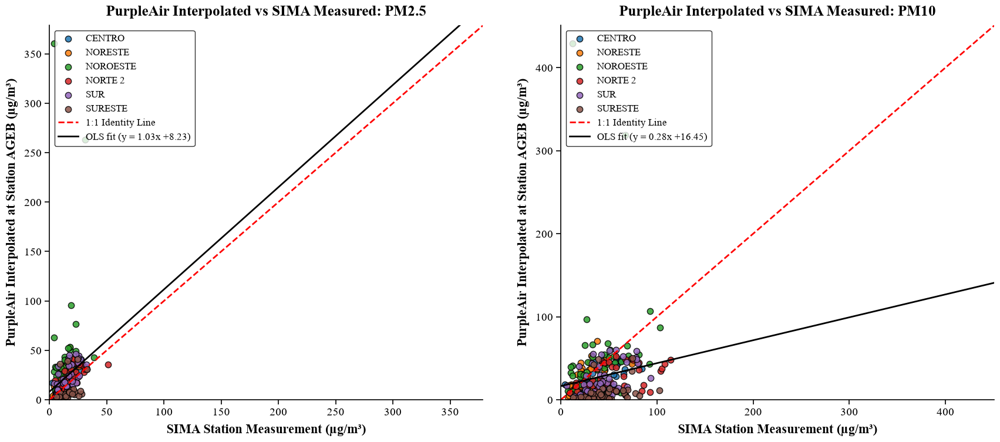

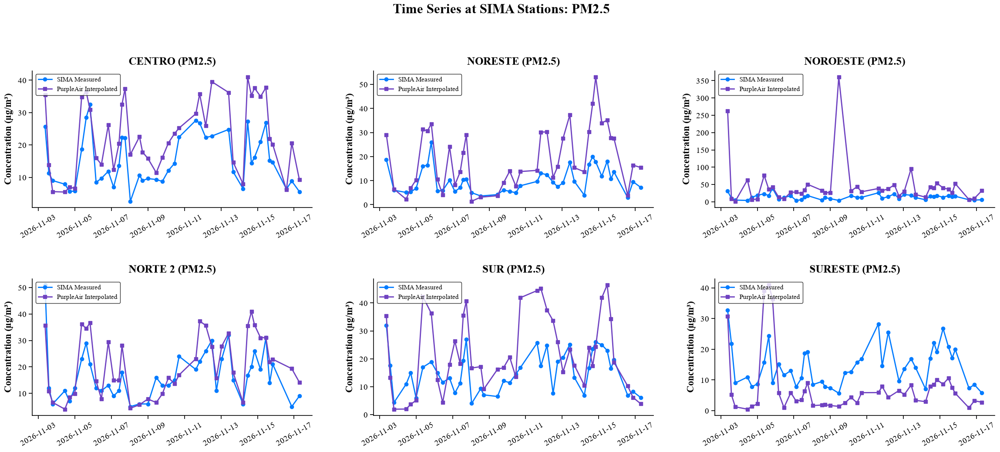

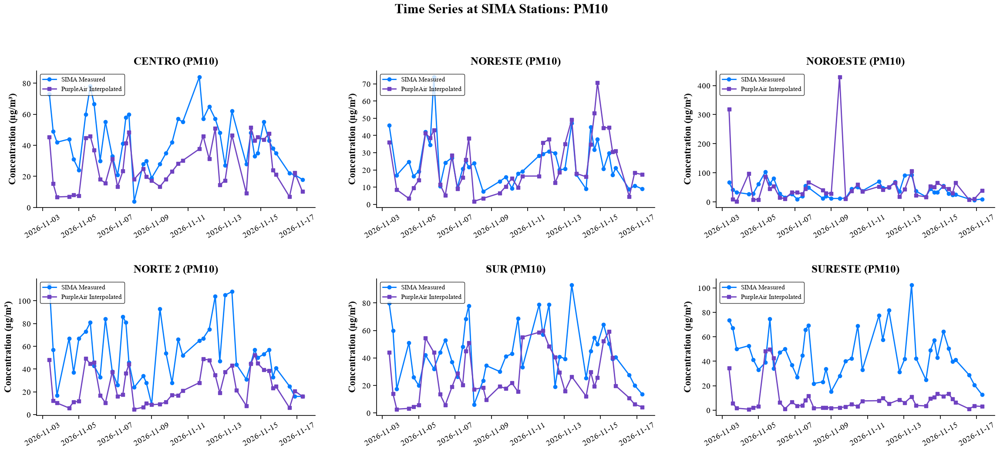

Table saved to resultados\validacion_estaciones_sima.csv


In [32]:
# =============================================================================
# BLOQUE 7 · Validación contra lecturas reales de las estaciones SIMA
# =============================================================================
CSV_ESTACIONES = RAIZ / "SIMA" / "sima_meteo_historico.csv"
VALORES_INVALIDOS = ["ND", "-9999", "-9999.0"]      # códigos de dato faltante en el archivo
EPA_PM25 = {"r2_min": 0.70, "pendiente": (0.65, 1.35), "intercepto": (-5, 5), "rmse_max": 7}
R_TIERRA_KM = 6371.0

faltan = [v for v in ("banner", "metricas_ageb", "clasificar", "pa_total", "sima_total", "ubicaciones")
          if v not in globals()]
if faltan:
    raise RuntimeError(f"Run the coverage cell, BLOQUE 0 and BLOQUE 2 first. Missing: {', '.join(faltan)}")


def leer_estaciones(ruta):
    """Lecturas de estación en formato largo, con la misma limpieza de fechas que el resto del notebook."""
    df = pd.read_csv(ruta, encoding="utf-8-sig", na_values=VALORES_INVALIDOS, low_memory=False,
                     usecols=["timestamp", "Estacion", "PM25_ugm3", "PM10_ugm3", "lat", "lon"])
    df = df.rename(columns={"Estacion": "estacion", "PM25_ugm3": "PM2.5", "PM10_ugm3": "PM10"})
    fechas = pd.to_datetime(df["timestamp"], errors="coerce", utc=True, format="mixed")
    df["timestamp"] = fechas.dt.tz_localize(None).dt.floor("h") + pd.Timedelta(hours=OFFSET_HORAS["SIMA"])
    df["estacion"] = df["estacion"].astype(str).str.strip()
    for c in CONTAMINANTES:
        df[c] = pd.to_numeric(df[c], errors="coerce")
        df.loc[df[c] < 0, c] = np.nan                     # cualquier negativo restante es inválido
    inconsistentes = df["PM2.5"] > df["PM10"]             # PM2.5 no puede superar a PM10
    df.loc[inconsistentes, CONTAMINANTES] = np.nan
    df = df.dropna(subset=["timestamp"]).drop_duplicates(["timestamp", "estacion"], keep="last")
    return df.reset_index(drop=True), int(inconsistentes.sum())


def ageb_de_estaciones(est):
    """AGEB que contiene cada estación: unión espacial con el SHP; si no hay SHP, por nombre en `ubicaciones`."""
    puntos = est.drop_duplicates("estacion")[["estacion", "lat", "lon"]].reset_index(drop=True)
    if agebs_gdf is not None and gpd is not None:
        g = gpd.GeoDataFrame(puntos, geometry=gpd.points_from_xy(puntos["lon"], puntos["lat"]), crs="EPSG:4326")
        unidos = gpd.sjoin(g, agebs_gdf[["cvegeo", "geometry"]], how="left", predicate="within")
        return pd.DataFrame(unidos[["estacion", "lat", "lon", "cvegeo"]]).drop_duplicates("estacion")
    nombres = ubicaciones.loc[ubicaciones["red"] == "SIMA", ["nombre", "cvegeo"]]
    nombres = nombres.assign(clave=nombres["nombre"].str.upper().str.strip())
    return (puntos.assign(clave=puntos["estacion"].str.upper())
            .merge(nombres[["clave", "cvegeo"]], on="clave", how="left").drop(columns="clave"))


def km_al_sensor_pa_mas_cercano(lat, lon):
    pa_pts = ubicaciones[ubicaciones["red"] == "PurpleAir"].dropna(subset=["lat", "lon"])
    if pa_pts.empty:
        return np.full(len(lat), np.nan)
    la1, lo1 = np.radians(np.asarray(lat))[:, None], np.radians(np.asarray(lon))[:, None]
    la2, lo2 = np.radians(pa_pts["lat"].to_numpy())[None, :], np.radians(pa_pts["lon"].to_numpy())[None, :]
    h = np.sin((la2 - la1) / 2) ** 2 + np.cos(la1) * np.cos(la2) * np.sin((lo2 - lo1) / 2) ** 2
    return (2 * R_TIERRA_KM * np.arcsin(np.sqrt(h))).min(axis=1)


def emparejar(est, estimado, nombre_estimado):
    """Une lecturas de estación con un producto interpolado (PurpleAir o SIMA) en el AGEB de la estación."""
    largo = []
    for c in CONTAMINANTES:
        m = (est[["timestamp", "estacion", "cvegeo", c]].rename(columns={c: "SIMA"})
             .merge(estimado[["timestamp", "cvegeo", c]].rename(columns={c: "PurpleAir"}),
                    on=["timestamp", "cvegeo"], how="inner").dropna(subset=["SIMA", "PurpleAir"]))
        largo.append(m.assign(contaminante=c))
    p = pd.concat(largo, ignore_index=True)
    p["estimado"] = nombre_estimado
    return p


def metricas_por_estacion(p):
    t = (p.groupby(["contaminante", "estacion"])[["timestamp", "SIMA", "PurpleAir"]]
         .apply(metricas_ageb).reset_index())
    t["q"] = np.nan
    for c, idx in t.groupby("contaminante").groups.items():
        ok = t.loc[idx, "p"].dropna()
        if len(ok):
            t.loc[ok.index, "q"] = stats.false_discovery_control(ok)
    t["confidence"] = pd.Categorical(t.apply(clasificar, axis=1), categories=CLASES, ordered=True)
    return t


# --- 1. Lectura y ubicación de las estaciones ---------------------------------------------------
estaciones, n_inconsistentes = leer_estaciones(CSV_ESTACIONES)
ubic_est = ageb_de_estaciones(estaciones)
ubic_est["dist_PurpleAir_km"] = km_al_sensor_pa_mas_cercano(ubic_est["lat"], ubic_est["lon"])
ubic_est["en_cobertura_PA"] = ubic_est["cvegeo"].isin(set(pa_total["cvegeo"]))
estaciones = estaciones.merge(ubic_est[["estacion", "cvegeo"]], on="estacion", how="left")

banner("SIMA STATION READINGS (RAW)")
print(f"File: {CSV_ESTACIONES.relative_to(RAIZ)}")
print(f"Stations: {estaciones['estacion'].nunique()} | Timestamps: {estaciones['timestamp'].nunique()} | "
      f"Span: {estaciones['timestamp'].min():%Y-%m-%d %H:%M} to {estaciones['timestamp'].max():%Y-%m-%d %H:%M}")
for c in CONTAMINANTES:
    print(f"{c:<6} valid readings: {estaciones[c].notna().sum():,} / {len(estaciones):,} "
          f"({100 * estaciones[c].notna().mean():.1f} %)")
print(f"Rows discarded because PM2.5 > PM10: {n_inconsistentes}")
print("\n-- Station location --")
tabla(ubic_est.set_index("estacion")[["cvegeo", "en_cobertura_PA", "dist_PurpleAir_km"]], 2)
cierre()

# --- 2. Emparejamiento: PurpleAir interpolado vs estación, y SIMA interpolado vs estación --------
dentro = estaciones[estaciones["cvegeo"].isin(set(pa_total["cvegeo"]))]
pares_pa = emparejar(dentro, pa_total, "PurpleAir interpolated")
pares_si = emparejar(dentro, sima_total, "SIMA interpolated")

if pares_pa.empty:
    print("No PurpleAir estimate coincides in time and AGEB with any station reading.")
else:
    val_pa = metricas_por_estacion(pares_pa).merge(ubic_est[["estacion", "dist_PurpleAir_km"]], on="estacion")
    val_si = metricas_por_estacion(pares_si) if not pares_si.empty else None
    cols = ["n", "r", "r_ci_lo", "r_ci_hi", "q", "MBE", "NMB_pct", "RMSE", "slope", "intercept",
            "confidence", "dist_PurpleAir_km"]

    for c in CONTAMINANTES:
        v = val_pa[val_pa["contaminante"] == c].set_index("estacion")
        s = pares_pa[pares_pa["contaminante"] == c]
        banner(f"STATION VALIDATION — PURPLEAIR vs MEASURED SIMA: {c}")
        print(f"Stations with matches: {len(v)} | Matched hours: {len(s):,} "
              f"(per station: {v['n'].min():.0f}–{v['n'].max():.0f})")
        print("\n-- Per Station --")
        tabla(v[cols], 2)

        r_all = stats.pearsonr(s["SIMA"], s["PurpleAir"])[0] if len(s) > 2 else np.nan
        pend, inter = np.polyfit(s["SIMA"], s["PurpleAir"], 1) if len(s) > 2 else (np.nan, np.nan)
        d = s["PurpleAir"] - s["SIMA"]
        print("\n-- All Stations Pooled --")
        print(f"Pearson r: {r_all:.3f} (R² = {r_all ** 2:.3f}) | Slope: {pend:.2f} | Intercept: {inter:.2f} µg/m³")
        print(f"MBE: {d.mean():.2f} µg/m³ | NMB: {100 * d.sum() / s['SIMA'].sum():.1f} % | "
              f"RMSE: {np.sqrt((d ** 2).mean()):.2f} µg/m³")

        if c == "PM2.5":
            e = EPA_PM25
            cumple = ((v["r"] ** 2 >= e["r2_min"]) & v["slope"].between(*e["pendiente"])
                      & v["intercept"].between(*e["intercepto"]) & (v["RMSE"] <= e["rmse_max"]))
            print(f"\nStations meeting all EPA (2021) hourly PM2.5 targets: {int(cumple.sum())} / {len(v)}")
            print("Targets: R² ≥ 0.70 | slope 1 ± 0.35 | intercept −5 to 5 µg/m³ | RMSE ≤ 7 µg/m³")

        if val_si is not None:
            w = val_si[val_si["contaminante"] == c]
            print("\n-- Reference Check: SIMA Interpolated Surface vs Measured SIMA --")
            print(f"Median r: {w['r'].median():.3f} | Median RMSE: {w['RMSE'].median():.2f} µg/m³ | "
                  f"Median NMB: {w['NMB_pct'].median():.1f} %")
            print("(Low error here means the SIMA surface used in BLOQUES 2–5 is a fair reference.)")
        cierre()

    # --- 3. Figuras ------------------------------------------------------------------------------
    nombres = sorted(pares_pa["estacion"].unique())
    paleta = dict(zip(nombres, plt.cm.tab10.colors))

    fig, axes = nueva_figura(1, len(CONTAMINANTES), (9 * len(CONTAMINANTES), 8.5))
    for ax, c in zip(axes[0], CONTAMINANTES):
        s = pares_pa[pares_pa["contaminante"] == c]
        for nombre, g in s.groupby("estacion"):
            ax.scatter(g["SIMA"], g["PurpleAir"], s=55, alpha=0.85, color=paleta[nombre], edgecolor="black", label=nombre)
        lim = max(s["SIMA"].max(), s["PurpleAir"].max()) * 1.05
        ax.plot([0, lim], [0, lim], "r--", lw=2, label="1:1 Identity Line")
        if len(s) > 2:
            pend, inter = np.polyfit(s["SIMA"], s["PurpleAir"], 1)
            ax.plot([0, lim], [inter, inter + pend * lim], color="black", lw=2,
                    label=f"OLS fit (y = {pend:.2f}x {inter:+.2f})")
        ax.set_xlim(0, lim)
        ax.set_ylim(0, lim)
        ax.set_title(f"PurpleAir Interpolated vs SIMA Measured: {c}", fontweight="bold", pad=12)
        ax.set_xlabel("SIMA Station Measurement (µg/m³)")
        ax.set_ylabel("PurpleAir Interpolated at Station AGEB (µg/m³)")
        leyenda(ax, loc="upper left", fontsize=12)
    plt.tight_layout(pad=3.0)
    guardar(fig, "validacion_estaciones_sima_medido")
    plt.show()

    columnas = 3
    filas = int(np.ceil(len(nombres) / columnas))
    for c in CONTAMINANTES:
        s = pares_pa[pares_pa["contaminante"] == c]
        fig, axes = nueva_figura(filas, columnas, (8 * columnas, 5.5 * filas))
        for ax, nombre in zip(axes.flat, nombres):
            g = s[s["estacion"] == nombre].sort_values("timestamp")
            ax.plot(g["timestamp"], g["SIMA"], marker="o", ms=6, lw=2, color=COLOR_SIMA, label="SIMA Measured")
            ax.plot(g["timestamp"], g["PurpleAir"], marker="s", ms=6, lw=2, color=COLOR_PA, label="PurpleAir Interpolated")
            ax.set_title(f"{nombre} ({c})", fontweight="bold", pad=10)
            ax.set_ylabel("Concentration (µg/m³)")
            ax.tick_params(axis="x", rotation=30)
            leyenda(ax, loc="upper left", fontsize=11)
        for ax in list(axes.flat)[len(nombres):]:
            ax.set_visible(False)
        fig.suptitle(f"Time Series at SIMA Stations: {c}", fontweight="bold", fontsize=22)
        plt.tight_layout(pad=3.0)
        guardar(fig, f"series_estaciones_{c.replace('.', '')}")
        plt.show()

    DIR_RESULTADOS.mkdir(exist_ok=True)
    val_pa.to_csv(DIR_RESULTADOS / "validacion_estaciones_sima.csv", index=False, encoding="utf-8-sig")
    print(f"Table saved to {DIR_RESULTADOS / 'validacion_estaciones_sima.csv'}")

### Geographic Coverage Alignment of SIMA and PurpleAir Data for Meteorological Parameters

In [28]:
import numpy as np
import pandas as pd
from pathlib import Path

# Geographic & Temporal Alignment for Meteorological Data
def align_meteorological_coverage(raiz_path, offset_pa=-6, offset_sima=0):
    csv_pa = raiz_path / "Purple Air" / "interpolacion_meteo_historico.csv"
    csv_sima = raiz_path / "SIMA" / "sima_interpolacion_historico.csv"

    # Read and clean SIMA Meteo
    df_sima = pd.read_csv(csv_sima, encoding="utf-8-sig", dtype={"CVEGEO": str}, na_values=["ND"], low_memory=False)
    df_sima = df_sima.rename(columns={
        "CVEGEO": "cvegeo",
        "Temperatura_C": "Temp_SIMA",
        "Humedad_pct": "RH_SIMA",
        "RadiacionSolar_Wm2": "SolarRad_SIMA"
    })
    fechas_sima = pd.to_datetime(df_sima["timestamp"], errors="coerce", utc=True, format="mixed")
    df_sima["timestamp"] = fechas_sima.dt.tz_localize(None).dt.floor("h") + pd.Timedelta(hours=offset_sima)
    df_sima["cvegeo"] = df_sima["cvegeo"].astype(str).str.strip().str.zfill(13)
    df_sima = df_sima.dropna(subset=["timestamp"]).drop_duplicates(["timestamp", "cvegeo"], keep="last")

    # Read and clean PurpleAir Meteo
    df_pa = pd.read_csv(csv_pa, encoding="utf-8-sig", dtype={"cvegeo": str}, na_values=["ND"], low_memory=False)
    df_pa = df_pa.rename(columns={
        "temperatura_interpolada_C": "Temp_PurpleAir",
        "humedad_interpolada_pct": "RH_PurpleAir"
    })
    fechas_pa = pd.to_datetime(df_pa["timestamp"], errors="coerce", utc=True, format="mixed")
    df_pa["timestamp"] = fechas_pa.dt.tz_localize(None).dt.floor("h") + pd.Timedelta(hours=offset_pa)
    df_pa["cvegeo"] = df_pa["cvegeo"].astype(str).str.strip().str.zfill(13)
    df_pa = df_pa.dropna(subset=["timestamp"]).drop_duplicates(["timestamp", "cvegeo"], keep="last")

    # Inner Join for Common Spatial and Temporal Coverage
    matched_meteo = pd.merge(
        df_pa[["timestamp", "cvegeo", "Temp_PurpleAir", "RH_PurpleAir"]],
        df_sima[["timestamp", "cvegeo", "Temp_SIMA", "RH_SIMA", "SolarRad_SIMA"]],
        on=["timestamp", "cvegeo"],
        how="inner"
    ).dropna(subset=["Temp_PurpleAir", "Temp_SIMA", "RH_PurpleAir", "RH_SIMA"])

    print(f"Total Matched Spatial-Temporal Records: {len(matched_meteo):,}")
    print(f"Common Coverage Unique AGEBs: {matched_meteo['cvegeo'].nunique()}")
    print(f"Time Horizon: {matched_meteo['timestamp'].min()} to {matched_meteo['timestamp'].max()}")

    return matched_meteo

# Run Alignment
df_meteo_pairs = align_meteorological_coverage(RAIZ)

Total Matched Spatial-Temporal Records: 49,701
Common Coverage Unique AGEBs: 790
Time Horizon: 2026-10-27 13:00:00 to 2026-11-17 16:00:00


### Statistical Tests and Exploratory Analysis of Meteorological Variables


 STATISTICAL TEST DIAGNOSTIC: RELATIVE HUMIDITY
Paired Records Count (n): 49,701
SIMA Reference -> Median: 72.57 % | IQR: 19.21
PurpleAir      -> Median: 51.20 % | IQR: 20.59
Difference Bias -> Median (PA - SIMA): -17.91 %

-- Correlation Matrix --
Pearson Correlation (Linearity): r = 0.437 (p-value: 0.00e+00)
Spearman Correlation (Monotonicity): r = 0.482 (p-value: 0.00e+00)



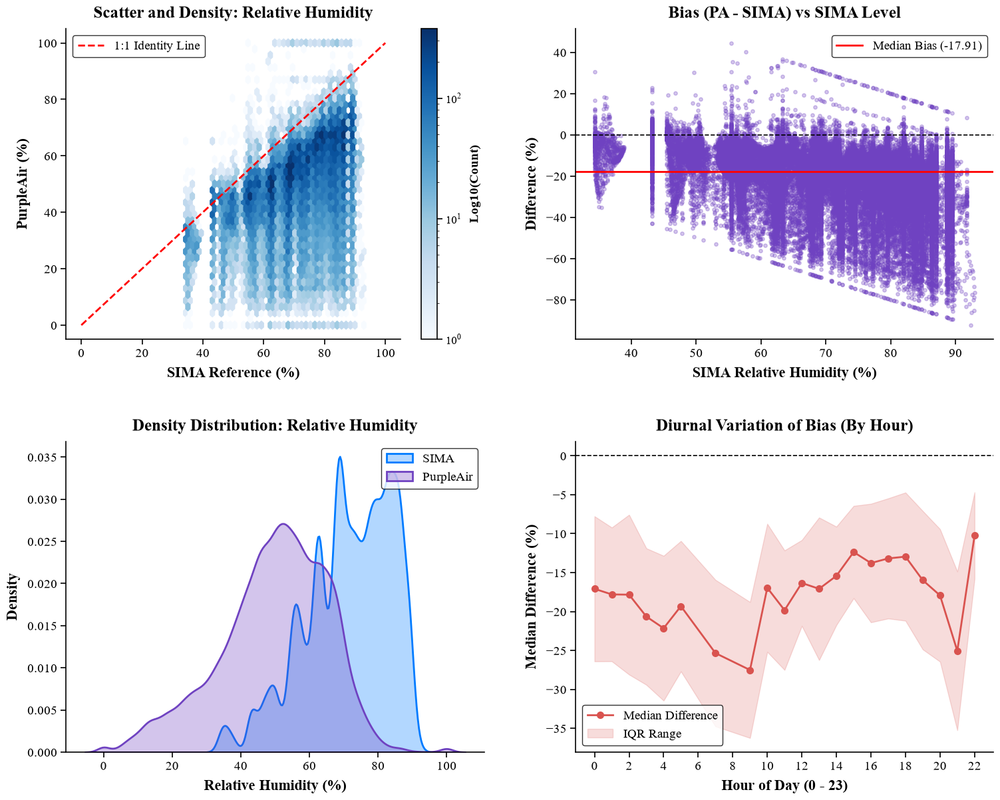


 STATISTICAL TEST DIAGNOSTIC: TEMPERATURE
Paired Records Count (n): 49,701
SIMA Reference -> Median: 21.61 °C | IQR: 4.98
PurpleAir      -> Median: 27.31 °C | IQR: 5.20
Difference Bias -> Median (PA - SIMA): 5.37 °C

-- Correlation Matrix --
Pearson Correlation (Linearity): r = 0.743 (p-value: 0.00e+00)
Spearman Correlation (Monotonicity): r = 0.759 (p-value: 0.00e+00)



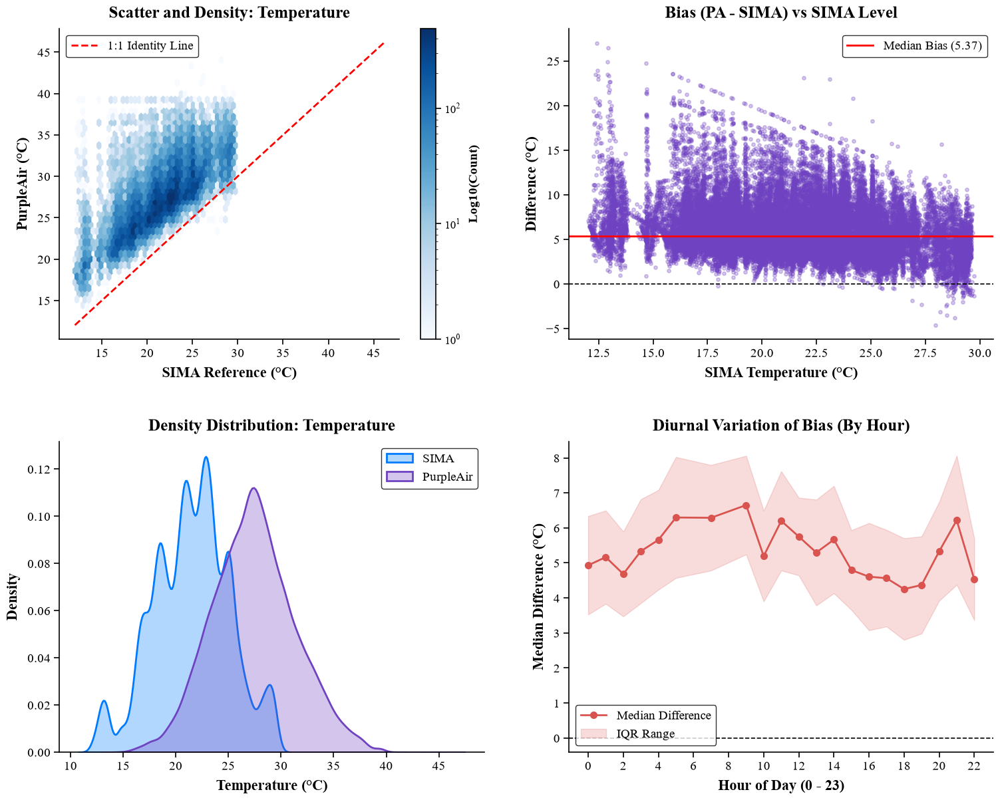

In [29]:
import scipy.stats as stats
import matplotlib.pyplot as plt
import seaborn as sns

# Global Style Setup (Times New Roman, English, No Grid, Large Fonts)
plt.rcParams.update({
    "font.family": "serif",
    "font.serif": ["Times New Roman"],
    "font.size": 14,
    "axes.labelsize": 16,
    "axes.titlesize": 18,
    "xtick.labelsize": 14,
    "ytick.labelsize": 14,
    "legend.fontsize": 14,
    "figure.titlesize": 20,
    "axes.grid": False
})

COLOR_PA = "#6f42c1"
COLOR_SIMA = "#007bff"
COLOR_DIF = "#d9534f"

def run_meteorological_statistical_tests(df_meteo):
    variables = [
        ("Relative Humidity", "RH_SIMA", "RH_PurpleAir", "%"),
        ("Temperature", "Temp_SIMA", "Temp_PurpleAir", "°C")
    ]
    
    for var_name, col_sima, col_pa, unit in variables:
        sub = df_meteo[[col_sima, col_pa, "timestamp"]].dropna().copy()
        sub["diferencia"] = sub[col_pa] - sub[col_sima]
        sub["hora"] = sub["timestamp"].dt.hour
        
        # 1. Statistical Calculations
        med_sima = sub[col_sima].median()
        iqr_sima = sub[col_sima].quantile(0.75) - sub[col_sima].quantile(0.25)
        
        med_pa = sub[col_pa].median()
        iqr_pa = sub[col_pa].quantile(0.75) - sub[col_pa].quantile(0.25)
        
        med_dif = sub["diferencia"].median()
        
        r_pearson, p_pearson = stats.pearsonr(sub[col_sima], sub[col_pa])
        r_spearman, p_spearman = stats.spearmanr(sub[col_sima], sub[col_pa])
        
        # 2. Console Summary Output
        print("\n" + "=" * 60)
        print(f" STATISTICAL TEST DIAGNOSTIC: {var_name.upper()}")
        print("=" * 60)
        print(f"Paired Records Count (n): {len(sub):,}")
        print(f"SIMA Reference -> Median: {med_sima:.2f} {unit} | IQR: {iqr_sima:.2f}")
        print(f"PurpleAir      -> Median: {med_pa:.2f} {unit} | IQR: {iqr_pa:.2f}")
        print(f"Difference Bias -> Median (PA - SIMA): {med_dif:.2f} {unit}")
        print("\n-- Correlation Matrix --")
        print(f"Pearson Correlation (Linearity): r = {r_pearson:.3f} (p-value: {p_pearson:.2e})")
        print(f"Spearman Correlation (Monotonicity): r = {r_spearman:.3f} (p-value: {p_spearman:.2e})")
        print("=" * 60 + "\n")
        
        # 3. Figure Generation (2x2 Panel)
        fig, axes = plt.subplots(2, 2, figsize=(16, 13), facecolor="white")
        fig.patch.set_facecolor("white")
        
        for ax in axes.flat:
            ax.set_facecolor("white")
            for spine in ax.spines.values():
                spine.set_color("black")
                spine.set_linewidth(1.2)
                
        # Subplot 1: Hexbin Scatter Plot
        hb = axes[0, 0].hexbin(sub[col_sima], sub[col_pa], gridsize=40, cmap="Blues", mincnt=1, bins='log')
        max_val = max(sub[col_sima].max(), sub[col_pa].max())
        min_val = min(sub[col_sima].min(), sub[col_pa].min())
        axes[0, 0].plot([min_val, max_val], [min_val, max_val], 'r--', lw=2, label="1:1 Identity Line")
        axes[0, 0].set_title(f"Scatter and Density: {var_name}", fontweight="bold", pad=12)
        axes[0, 0].set_xlabel(f"SIMA Reference ({unit})")
        axes[0, 0].set_ylabel(f"PurpleAir ({unit})")
        axes[0, 0].legend(loc="upper left", frameon=True, edgecolor="black")
        
        cb = fig.colorbar(hb, ax=axes[0, 0])
        cb.set_label("Log10(Count)", fontsize=14)
        cb.ax.tick_params(labelsize=12)
        
        # Subplot 2: Bias Plot (Residuals)
        axes[0, 1].scatter(sub[col_sima], sub["diferencia"], alpha=0.3, color=COLOR_PA, s=15)
        axes[0, 1].axhline(0, color="black", linestyle="--", lw=1.2)
        axes[0, 1].axhline(med_dif, color="red", linestyle="-", lw=2, label=f"Median Bias ({med_dif:.2f})")
        axes[0, 1].set_title(f"Bias (PA - SIMA) vs SIMA Level", fontweight="bold", pad=12)
        axes[0, 1].set_xlabel(f"SIMA {var_name} ({unit})")
        axes[0, 1].set_ylabel(f"Difference ({unit})")
        axes[0, 1].legend(loc="upper right", frameon=True, edgecolor="black")
        
        # Subplot 3: KDE Density Distribution
        sns.kdeplot(sub[col_sima], ax=axes[1, 0], color=COLOR_SIMA, label="SIMA", fill=True, alpha=0.3, lw=2)
        sns.kdeplot(sub[col_pa], ax=axes[1, 0], color=COLOR_PA, label="PurpleAir", fill=True, alpha=0.3, lw=2)
        axes[1, 0].set_title(f"Density Distribution: {var_name}", fontweight="bold", pad=12)
        axes[1, 0].set_xlabel(f"{var_name} ({unit})")
        axes[1, 0].set_ylabel("Density")
        axes[1, 0].legend(loc="upper right", frameon=True, edgecolor="black")
        
        # Subplot 4: Diurnal Variation of Bias
        perfil_hora = sub.groupby("hora")["diferencia"].agg(["median", lambda x: x.quantile(0.75) - x.quantile(0.25)])
        perfil_hora.columns = ["mediana", "iqr"]
        
        axes[1, 1].plot(perfil_hora.index, perfil_hora["mediana"], marker="o", ms=7, color=COLOR_DIF, lw=2, label="Median Difference")
        axes[1, 1].fill_between(perfil_hora.index, perfil_hora["mediana"] - perfil_hora["iqr"]/2, 
                                perfil_hora["mediana"] + perfil_hora["iqr"]/2, color=COLOR_DIF, alpha=0.2, label="IQR Range")
        axes[1, 1].axhline(0, color="black", linestyle="--", lw=1.2)
        axes[1, 1].set_title("Diurnal Variation of Bias (By Hour)", fontweight="bold", pad=12)
        axes[1, 1].set_xlabel("Hour of Day (0 - 23)")
        axes[1, 1].set_ylabel(f"Median Difference ({unit})")
        axes[1, 1].set_xticks(range(0, 24, 2))
        axes[1, 1].legend(loc="lower left", frameon=True, edgecolor="black")
        
        plt.tight_layout(pad=3.0)
        plt.show()

# Run Statistical Test Suite
run_meteorological_statistical_tests(df_meteo_pairs)